# Computer Vision Numericals Solved by Hand: From Pixels to Detection, Segmentation and Style Transfer

> **Who is this for:** students preparing for a computer-vision or CNN exam or interview, and anyone who wants to *see* the arithmetic behind convolution, object detection and segmentation, with numbers small enough to do on paper.
>
> **What you will learn:**
> - Images as numbers: grayscale conversion, normalization, standardization and memory size
> - Convolution by hand: edge filters, padding, stride, the output-size formula, convolution over volumes, parameter and multiplication counts
> - Pooling, receptive fields, 1x1 bottlenecks, depthwise separable convolutions, residual blocks and EfficientNet compound scaling
> - Upsampling: transposed convolution and a full U-Net shape walk-through
> - Detection: the localization target vector, IoU, non-max suppression, anchor boxes, YOLO output sizes, precision/recall, AP and mAP
> - Segmentation metrics (pixel accuracy, IoU, Dice), face verification and triplet loss, Gram matrices for neural style transfer
> - Data augmentation counts, transfer-learning parameter counts, MSE/PSNR, and an FGSM adversarial example
> - For every problem: a step-by-step hand solution, a NumPy cell that re-computes it and checks it with `assert`, and a practice problem with a hidden answer
>
> **Prerequisites:** [Images and your first CNN](00_start_here_images_and_your_first_cnn.ipynb) (pixels, convolution, pooling) and [Deep learning numericals](../05_Deep_Learning/00b_dl_numericals_solved_by_hand.ipynb) (forward pass, ReLU, losses). School algebra; a calculator helps.
>
> **Time needed:** about 3-4 hours to work through every problem by hand (the code runs in a few seconds).
>
> **Runs on:** CPU, no API key, no internet. Only NumPy and matplotlib are needed. A few optional cross-checks use PyTorch if you have it and are skipped otherwise.

## Explained simply

A computer never "sees" a photo. It receives a **grid of numbers**: one number per pixel for a grayscale image, three numbers (red, green, blue) for a colour image. Everything in computer vision, from edge detection to self-driving cars, is arithmetic on those grids. Exam questions test whether you can do that arithmetic yourself, so this notebook works through it with tiny grids.

Everyday pictures for the main ideas:

- A **filter** (kernel) is a small stencil you slide over the photo. At each spot you multiply the numbers under the stencil by the stencil's numbers and add them up. A big result means "the pattern I am looking for is here".
- **Padding** is a frame of zeros around the photo so the stencil can also sit on the border. **Stride** is how many pixels you jump each time you move the stencil.
- **Pooling** summarizes each small block with one number, like describing a neighbourhood by its tallest building (max) or its average building height (average).
- **IoU** (intersection over union) asks: how much do two stickers overlap, compared with all the paper they cover together?
- **Non-max suppression** removes duplicate guesses: when five boxes point at the same cat, keep the most confident one.
- **AP and mAP** are a detector's report card: does it find the objects (recall) without many false alarms (precision)?
- **Dice and IoU for masks** use the same overlap idea, pixel by pixel.
- **Triplet loss** trains a "face fingerprint": photos of the same person should land close together, photos of different people far apart.

**How to use this notebook.** For each section: read the problem, try it on paper, compare with the hand solution, run the code cell (it re-computes everything with NumPy and `assert`s that the hand answer is right), then do the "Try it yourself" problem.

**Conventions used everywhere below.**
- In deep learning, "convolution" means **cross-correlation**: the kernel is *not* flipped. This is what PyTorch and TensorFlow compute.
- Shapes are written height × width × channels (H×W×C).
- Results are rounded to **4 decimal places**, but intermediate values are kept at full precision.
- Boxes are $(x_1, y_1, x_2, y_2)$ with $x$ to the right and $y$ **downwards** (image coordinates). Area $= (x_2 - x_1)(y_2 - y_1)$, with no "+1".

## Table of contents

| # | Section | You will compute |
|---|---|---|
| 0 | Setup | imports |
| 1 | Images as numbers | grayscale, scaling to [0, 1], per-channel standardization, memory size |
| 2 | Edge detection | vertical, horizontal and Sobel filter outputs on a 6×6 image |
| 3 | Padding, stride, output size, volumes | the output-size formula, RGB inputs with several filters |
| 4 | Parameter counting | conv vs dense parameters, a LeNet-style table filled layer by layer |
| 5 | Pooling | max and average pooling by hand, global average pooling |
| 6 | Computational cost | multiplications, 1×1 bottleneck, depthwise separable convolution |
| 7 | Receptive field | stacked conv/pool layers, dilated convolutions |
| 8 | Residual block | a skip connection with numbers, why the identity is easy |
| 9 | EfficientNet compound scaling | depth, width, resolution and FLOPs for φ = 1, 2 |
| 10 | Transposed convolution | output size and a 2×2 → 3×3 and 2×2 → 4×4 example |
| 11 | U-Net shape walk-through | encoder halving, decoder doubling, skip concatenation |
| 12 | Object localization | the target vector y and its loss |
| 13 | Intersection over Union | IoU of two boxes |
| 14 | Non-max suppression | NMS on 5 boxes |
| 15 | Anchor boxes and YOLO | anchor assignment, YOLO output volume size |
| 16 | Detection evaluation | precision, recall, AP (all-point and 11-point), mAP |
| 17 | Segmentation metrics | pixel accuracy, IoU, Dice on 4×4 masks |
| 18 | Face verification and triplet loss | embedding distances, triplet loss |
| 19 | Neural style transfer | Gram matrix, style cost, content cost |
| 20 | Augmentation and transfer learning | counting variants, frozen vs trainable parameters |
| 21 | Image quality | MSE and PSNR |
| 22 | Adversarial examples | FGSM on a 4-pixel image |
|  | Recap cheat sheet | every formula in one table |

## 0. Setup

Only NumPy (for the arithmetic) and matplotlib (for four small figures) are needed. PyTorch is optional: if it is installed, a few cells also cross-check the NumPy results with PyTorch's own layers.

In [1]:
import numpy as np                          # all the arithmetic
import matplotlib.pyplot as plt             # a few small figures
from matplotlib.patches import Rectangle    # boxes in the detection figures

np.set_printoptions(precision=4, suppress=True)   # print 4 decimals, no scientific notation

# Colours used in the figures (blue, orange, aqua) and the text colour
C_BLUE, C_ORANGE, C_AQUA, INK = "#2a78d6", "#eb6834", "#1baf7a", "#0b0b0b"

print("NumPy", np.__version__)
try:
    import torch
    print("PyTorch", torch.__version__, "found: the optional cross-checks will run")
except ImportError:
    print("PyTorch not installed: the optional cross-checks will print 'skipped: needs torch'")

NumPy 2.1.3
PyTorch not installed: the optional cross-checks will print 'skipped: needs torch'


## 1. Images as numbers

**What it is.** A digital image is a grid of pixels. A grayscale pixel is one number (for 8-bit images, 0 = black and 255 = white). A colour pixel is three numbers: red, green and blue (RGB).

**Analogy.** A mosaic: every tile has a colour, written down as three paint amounts.

**How it works.** An image is stored as an array of shape H×W×C. Neural networks train best on small numbers centred near 0, so images are first scaled to [0, 1] and often standardized channel by channel.

### Problem

A tiny 2×2 RGB image (8-bit) has these pixels:

| pixel (row, col) | R | G | B |
|---|---|---|---|
| (0, 0) | 100 | 50 | 200 |
| (0, 1) | 150 | 100 | 0 |
| (1, 0) | 200 | 150 | 50 |
| (1, 1) | 250 | 200 | 100 |

(a) Convert every pixel to grayscale with $Y = 0.299R + 0.587G + 0.114B$.

(b) Normalize the grayscale image to [0, 1].

(c) Standardize the **R channel** with its own mean and standard deviation (per-channel standardization, population standard deviation: divide by $N$).

(d) A pretrained model expects the red channel as $(R/255 - 0.485)/0.229$. What does the red value of pixel (0, 0) become?

(e) How many bytes does a 1920×1080 RGB image take as 8-bit integers (`uint8`, 1 byte per value)? As 32-bit floats (`float32`, 4 bytes per value)?

### Solution by hand

**Step 1 - grayscale (a weighted sum of R, G, B).**

- (0, 0): $0.299(100) + 0.587(50) + 0.114(200) = 29.9 + 29.35 + 22.8 = 82.05$
- (0, 1): $0.299(150) + 0.587(100) + 0.114(0) = 44.85 + 58.7 + 0 = 103.55$
- (1, 0): $0.299(200) + 0.587(150) + 0.114(50) = 59.8 + 88.05 + 5.7 = 153.55$
- (1, 1): $0.299(250) + 0.587(200) + 0.114(100) = 74.75 + 117.4 + 11.4 = 203.55$

The weights add up to $0.299 + 0.587 + 0.114 = 1$, so the result stays between 0 and 255. Green gets the largest weight because human eyes are most sensitive to green.

**Step 2 - normalize to [0, 1]: divide by 255.**

$82.05/255 = 0.3218$, $\;103.55/255 = 0.4061$, $\;153.55/255 = 0.6022$, $\;203.55/255 = 0.7982$

**Step 3 - standardize the R channel** $R = [100, 150, 200, 250]$.

- mean: $\mu = (100 + 150 + 200 + 250)/4 = 700/4 = 175$
- deviations $x - \mu$: $-75, -25, 25, 75$; squares: $5625, 625, 625, 5625$; sum $= 12500$
- variance $= 12500/4 = 3125$, standard deviation $\sigma = \sqrt{3125} = 55.9017$
- $z = (x - \mu)/\sigma$: $-75/55.9017 = -1.3416$, $\;-25/55.9017 = -0.4472$, $\;0.4472$, $\;1.3416$

The standardized channel has mean 0 and standard deviation 1.

**Step 4 - pretrained-model normalization.** $100/255 = 0.392157$ (keep the full value), then
$(0.392157 - 0.485)/0.229 = -0.092843/0.229 = -0.4054$.
(If you round 100/255 to 0.3922 too early you get $-0.4052$: round only at the end.)

**Step 5 - memory.** $1920 \times 1080 \times 3 = 6{,}220{,}800$ values.
- `uint8`: $6{,}220{,}800 \times 1 = 6{,}220{,}800$ bytes $\approx 6.2208$ MB ($\approx 5.9326$ MiB, using $2^{20}$ bytes per MiB)
- `float32`: $6{,}220{,}800 \times 4 = 24{,}883{,}200$ bytes $\approx 24.8832$ MB

In [2]:
img = np.array([[[100,  50, 200], [150, 100,   0]],
                [[200, 150,  50], [250, 200, 100]]], dtype=np.uint8)   # shape (H, W, C) = (2, 2, 3)
print("shape (H, W, C):", img.shape)

gray = img.astype(float) @ np.array([0.299, 0.587, 0.114])   # (a) weighted sum over the channel axis
gray01 = gray / 255                                            # (b) scale to [0, 1]
R = img[..., 0].astype(float)
R_z = (R - R.mean()) / R.std()                                 # (c) np.std divides by N by default
r00 = (100 / 255 - 0.485) / 0.229                              # (d)
n_values = 1920 * 1080 * 3                                     # (e)

print("(a) grayscale:\n", gray)
print("(b) normalized:\n", gray01)
print(f"(c) mean = {R.mean()}, std = {R.std():.4f}, z =\n", R_z)
print(f"(d) {r00:.4f}")
print(f"(e) uint8: {n_values:,} bytes = {n_values / 1e6:.4f} MB | float32: {n_values * 4:,} bytes")

assert np.allclose(gray, [[82.05, 103.55], [153.55, 203.55]])
assert np.allclose(gray01, [[0.3218, 0.4061], [0.6022, 0.7982]], atol=1e-4)
assert R.mean() == 175 and np.isclose(R.std(), 55.9017, atol=1e-4)
assert np.allclose(R_z, [[-1.3416, -0.4472], [0.4472, 1.3416]], atol=1e-4)
assert np.isclose(R_z.mean(), 0) and np.isclose(R_z.std(), 1)
R01 = R / 255                                                  # exam tip: same z-scores after dividing by 255
assert np.allclose((R01 - R01.mean()) / R01.std(), R_z)
assert np.isclose(r00, -0.4054, atol=1e-4)
assert n_values == 6_220_800 and n_values * 4 == 24_883_200 and np.isclose(n_values / 2**20, 5.9326, atol=1e-4)

# Common mistake: arithmetic on uint8 arrays wraps around (300 - 256 = 44)
a, b = np.array([200], dtype=np.uint8), np.array([100], dtype=np.uint8)
print("uint8: 200 + 100 =", a + b, "| as float:", a.astype(float) + b)
assert (a + b)[0] == 44
print("All checks passed.")

shape (H, W, C): (2, 2, 3)
(a) grayscale:
 [[ 82.05 103.55]
 [153.55 203.55]]
(b) normalized:
 [[0.3218 0.4061]
 [0.6022 0.7982]]
(c) mean = 175.0, std = 55.9017, z =
 [[-1.3416 -0.4472]
 [ 0.4472  1.3416]]
(d) -0.4054
(e) uint8: 6,220,800 bytes = 6.2208 MB | float32: 24,883,200 bytes
uint8: 200 + 100 = [44] | as float: [300.]
All checks passed.


### Try it yourself

A pixel has (R, G, B) = (50, 100, 150). (a) What is its grayscale value? (b) Its value normalized to [0, 1]? (c) How many bytes does a 640×480 RGB image take in `uint8` and in `float32`?

<details><summary>Answer</summary>

(a) $0.299(50) + 0.587(100) + 0.114(150) = 14.95 + 58.7 + 17.1 = 90.75$
(b) $90.75/255 = 0.3559$
(c) $640 \times 480 \times 3 = 921{,}600$ bytes in `uint8`; $\times 4 = 3{,}686{,}400$ bytes in `float32`.

</details>

**Common mistake:** doing arithmetic on `uint8` arrays. $200 + 100$ silently wraps around to $44$ instead of $300$ (the code above shows it). Convert to `float` first.

**Exam tip:** standardizing gives the same z-scores whether or not you divide by 255 first, because scaling changes the mean and the standard deviation by the same factor.

## 2. Edge detection with filters (vertical, horizontal, Sobel)

**What it is.** An edge is a place where the brightness changes quickly. An edge filter is a small grid of numbers (a kernel) that gives a large output where brightness changes in one direction, and 0 on flat areas.

**Analogy.** Running a finger across a table: you feel nothing on the flat top and a bump at the edge.

**How it works.** Slide the 3×3 kernel over the image. At each position, multiply the 9 pairs of numbers and add them up (cross-correlation, no flip). A 6×6 image and a 3×3 kernel with no padding give a $(6 - 3 + 1) \times (6 - 3 + 1) = 4 \times 4$ output.

### Problem

The 6×6 grayscale image $X$ has a bright 3×3 square (value 5) in the top-left corner on a dark background (value 0):

$$X = \begin{bmatrix} 5&5&5&0&0&0\\ 5&5&5&0&0&0\\ 5&5&5&0&0&0\\ 0&0&0&0&0&0\\ 0&0&0&0&0&0\\ 0&0&0&0&0&0 \end{bmatrix}$$

Apply each filter with stride 1 and no padding, and interpret the outputs:

$$K_v = \begin{bmatrix}1&0&-1\\1&0&-1\\1&0&-1\end{bmatrix} \text{ (vertical edges)},\quad
K_h = \begin{bmatrix}1&1&1\\0&0&0\\-1&-1&-1\end{bmatrix} \text{ (horizontal edges)},\quad
K_s = \begin{bmatrix}1&0&-1\\2&0&-2\\1&0&-1\end{bmatrix} \text{ (Sobel, vertical edges)}$$

### Solution by hand

**Step 1 - output size.** $(6 - 3)/1 + 1 = 4$, so each output is 4×4. Output $(i, j)$ uses rows $i$ to $i+2$ and columns $j$ to $j+2$ of $X$.

**Step 2 - vertical filter.** $K_v$ computes (sum of the window's left column) $-$ (sum of its right column).

- $(0,0)$: columns 0-2 are all 5: left $= 5+5+5 = 15$, right $= 15$, output $= 0$
- $(0,1)$: columns 1-3: left (column 1) $= 15$, right (column 3) $= 0$, output $= 15$
- $(0,2)$: columns 2-4: left (column 2) $= 15$, right (column 4) $= 0$, output $= 15$
- $(0,3)$: columns 3-5: $0 - 0 = 0$
- $(1,1)$: rows 1-3: left column $= 5 + 5 + 0 = 10$, right $= 0$, output $= 10$
- $(2,1)$: rows 2-4: left column $= 5 + 0 + 0 = 5$, output $= 5$
- row 3 (rows 3-5 of $X$) is all zeros, so the output is 0

$$Y_v = \begin{bmatrix}0&15&15&0\\0&10&10&0\\0&5&5&0\\0&0&0&0\end{bmatrix}$$

**Step 3 - horizontal filter.** $K_h$ computes (window's top row) $-$ (bottom row). For example $(1,0)$: rows 1-3, columns 0-2: top row (row 1) $= 15$, bottom row (row 3) $= 0$, output $= 15$; $(1,1)$: columns 1-3: top $= 5+5+0 = 10$; $(1,2)$: top $= 5 + 0 + 0 = 5$. Because the image is symmetric across its diagonal, $Y_h = Y_v^T$:

$$Y_h = \begin{bmatrix}0&0&0&0\\15&10&5&0\\15&10&5&0\\0&0&0&0\end{bmatrix}$$

**Step 4 - Sobel.** Same as $K_v$ but the middle row counts double (weights 1, 2, 1):

- $(0,1)$: $1(5) + 2(5) + 1(5) - 0 = 20$
- $(1,1)$: rows 1-3: $1(5) + 2(5) + 1(0) = 15$
- $(2,1)$: rows 2-4: $1(5) + 2(0) + 1(0) = 5$

$$Y_s = \begin{bmatrix}0&20&20&0\\0&15&15&0\\0&5&5&0\\0&0&0&0\end{bmatrix}$$

**Step 5 - interpretation.**
- $Y_v$ is non-zero only in columns 1-2, where the window straddles the square's **right side**. $Y_h$ is non-zero only where the window straddles the square's **bottom side**. Flat regions give 0.
- Positive values mean "bright on the left (or top), dark on the right (or bottom)". A dark-to-bright edge gives **negative** values (see the practice problem). Use $|Y|$ if you only care where the edges are.
- Values fade from 15 to 5 near the corner because the window covers only part of the square there.
- Sobel's 1-2-1 weights give a stronger response that is less sensitive to noise, because the centre row counts most and the outer rows smooth.

In [3]:
def conv2d(x, k, stride=1, pad=0):
    """Deep-learning 'convolution' (cross-correlation): slide k over x, multiply and add."""
    x = np.pad(np.asarray(x, dtype=float), pad)          # zeros around every side
    f = k.shape[0]
    h_out = (x.shape[0] - f) // stride + 1
    w_out = (x.shape[1] - f) // stride + 1
    out = np.zeros((h_out, w_out))
    for i in range(h_out):
        for j in range(w_out):
            window = x[i * stride:i * stride + f, j * stride:j * stride + f]
            out[i, j] = np.sum(window * k)
    return out

X = np.zeros((6, 6)); X[:3, :3] = 5                      # bright 3x3 square in the top-left corner
K_v = np.array([[1, 0, -1], [1, 0, -1], [1, 0, -1]])     # vertical edges
K_h = K_v.T                                              # [[1,1,1],[0,0,0],[-1,-1,-1]]: horizontal edges
K_s = np.array([[1, 0, -1], [2, 0, -2], [1, 0, -1]])     # Sobel, vertical edges

Y_v, Y_h, Y_s = conv2d(X, K_v), conv2d(X, K_h), conv2d(X, K_s)
print("vertical:\n", Y_v, "\nhorizontal:\n", Y_h, "\nSobel:\n", Y_s)

assert np.array_equal(Y_v, [[0, 15, 15, 0], [0, 10, 10, 0], [0, 5, 5, 0], [0, 0, 0, 0]])
assert np.array_equal(Y_h, [[0, 0, 0, 0], [15, 10, 5, 0], [15, 10, 5, 0], [0, 0, 0, 0]])
assert np.array_equal(Y_s, [[0, 20, 20, 0], [0, 15, 15, 0], [0, 5, 5, 0], [0, 0, 0, 0]])
assert np.array_equal(conv2d(np.full((6, 6), 7.0), K_v), np.zeros((4, 4)))   # flat image -> no edges
print("All checks passed.")

# Optional cross-check with PyTorch's own convolution
try:
    import torch
    import torch.nn.functional as F
    t = F.conv2d(torch.tensor(X, dtype=torch.float32)[None, None],
                 torch.tensor(K_v, dtype=torch.float32)[None, None])
    assert np.allclose(t[0, 0].numpy(), Y_v)
    print("PyTorch F.conv2d agrees.")
except ImportError:
    print("skipped: needs torch")

vertical:
 [[ 0. 15. 15.  0.]
 [ 0. 10. 10.  0.]
 [ 0.  5.  5.  0.]
 [ 0.  0.  0.  0.]] 
horizontal:
 [[ 0.  0.  0.  0.]
 [15. 10.  5.  0.]
 [15. 10.  5.  0.]
 [ 0.  0.  0.  0.]] 
Sobel:
 [[ 0. 20. 20.  0.]
 [ 0. 15. 15.  0.]
 [ 0.  5.  5.  0.]
 [ 0.  0.  0.  0.]]
All checks passed.
skipped: needs torch


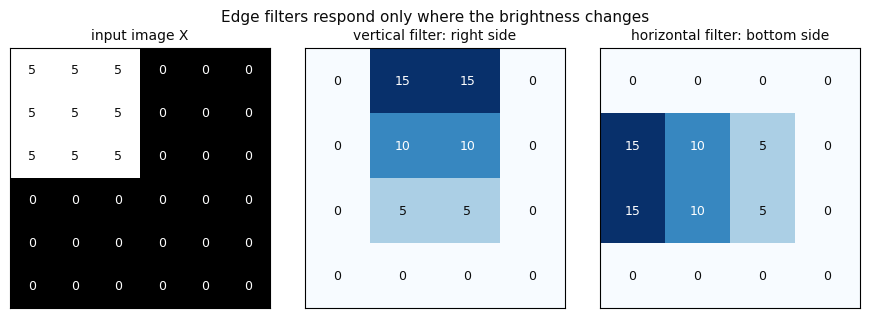

In [4]:
def show_grid(ax, M, title, cmap):
    """Draw a small matrix as an image with its numbers written in the cells."""
    ax.imshow(M, cmap=cmap, vmin=0, vmax=max(M.max(), 1))
    for (i, j), v in np.ndenumerate(M):
        dark_cell = v > M.max() / 2 if cmap == "Blues" else v <= M.max() / 2
        ax.text(j, i, f"{v:g}", ha="center", va="center", fontsize=9, color="white" if dark_cell else INK)
    ax.set_title(title, fontsize=10, color=INK)
    ax.set_xticks([]); ax.set_yticks([])

fig, axes = plt.subplots(1, 3, figsize=(9, 3.2))
show_grid(axes[0], X, "input image X", "gray")
show_grid(axes[1], Y_v, "vertical filter: right side", "Blues")
show_grid(axes[2], Y_h, "horizontal filter: bottom side", "Blues")
fig.suptitle("Edge filters respond only where the brightness changes", fontsize=11, color=INK)
plt.tight_layout()
plt.show()

### Try it yourself

A 6×6 image has its left 3 columns equal to 1 (dark) and its right 3 columns equal to 7 (bright). Apply $K_v$ (stride 1, no padding). What is the output, and what does its sign tell you?

<details><summary>Answer</summary>

Every row of the 4×4 output is $[0, -18, -18, 0]$. For example, columns 1-3: left column $1+1+1 = 3$, right column $7+7+7 = 21$, so $3 - 21 = -18$. The value is negative because the edge goes from dark (left) to bright (right).

</details>

**Exam tip:** every edge filter's weights add up to 0, so on a flat area (any constant value) the output is always 0.

## 3. Padding, stride, output size, and convolution over volumes

**What it is.** **Padding** $p$ adds a border of $p$ zeros around the image. **Stride** $s$ is how far the window jumps each step.

**Analogy.** Padding is a picture frame that lets the stencil sit on the edge of the photo; stride 2 is walking two steps at a time.

**How it works.** For an $n \times n$ input and an $f \times f$ filter:
$$n_{out} = \left\lfloor \frac{n + 2p - f}{s} \right\rfloor + 1$$
"Valid" means no padding ($p = 0$). "Same" means the output has the same size as the input (with $s = 1$), which needs $p = (f - 1)/2$. For a colour (volume) input, every filter has the **same depth as the input**, and each filter produces **one** output channel.

### Problem

(a) Find the output size in each case:

| case | n | f | p | s |
|---|---|---|---|---|
| A | 6 | 3 | 0 (valid) | 1 |
| B | 6 | 3 | same | 1 |
| C | 7 | 3 | 0 | 2 |
| D | 8 | 3 | 1 | 2 |
| E | 32 | 5 | 2 | 1 |
| F | 32 | 5 | 2 | 2 |
| G | 224 | 7 | 3 | 2 |

(b) An input of 15×15×3 goes through 4 filters of size 3×3 with stride 2 and padding 1. What is the shape of each filter, and of the output?

(c) A 3×3×2 input (2 channels) is convolved with **one** 2×2×2 filter, bias $b = 1$, stride 1, no padding. Compute the whole output.

$$\text{input channel 1} = \begin{bmatrix}1&2&0\\0&1&3\\2&1&0\end{bmatrix},\;
\text{input channel 2} = \begin{bmatrix}0&1&1\\2&0&1\\1&1&2\end{bmatrix},\;
\text{filter channel 1} = \begin{bmatrix}1&0\\0&-1\end{bmatrix},\;
\text{filter channel 2} = \begin{bmatrix}2&1\\0&1\end{bmatrix}$$

### Solution by hand

**Step 1 - the formula for each case.**

| case | computation | $n_{out}$ |
|---|---|---|
| A | $\lfloor (6 + 0 - 3)/1 \rfloor + 1 = 3 + 1$ | 4 |
| B | same: $p = (3-1)/2 = 1$, $\lfloor (6 + 2 - 3)/1 \rfloor + 1 = 5 + 1$ | 6 |
| C | $\lfloor (7 + 0 - 3)/2 \rfloor + 1 = 2 + 1$ | 3 |
| D | $\lfloor (8 + 2 - 3)/2 \rfloor + 1 = \lfloor 3.5 \rfloor + 1 = 3 + 1$ | 4 |
| E | $\lfloor (32 + 4 - 5)/1 \rfloor + 1 = 31 + 1$ ("same" padding) | 32 |
| F | $\lfloor (32 + 4 - 5)/2 \rfloor + 1 = \lfloor 15.5 \rfloor + 1 = 15 + 1$ | 16 |
| G | $\lfloor (224 + 6 - 7)/2 \rfloor + 1 = \lfloor 111.5 \rfloor + 1 = 111 + 1$ | 112 |

In D, F and G the floor drops the last half-step: the window would hang over the edge, so that position is not used. Case G is the first layer of a ResNet.

**Step 2 - volume shapes (b).** Each filter must match the input depth: **3×3×3**. Spatial size: $\lfloor (15 + 2 - 3)/2 \rfloor + 1 = 7 + 1 = 8$. One output channel per filter, so the output is **8×8×4**.

**Step 3 - convolution over a volume (c).** Output size $(3 - 2)/1 + 1 = 2$, so 2×2. Each filter channel slides over its own input channel, and the two results are **added together** with the bias into a single number.

- $(0,0)$: channel 1 window $\begin{bmatrix}1&2\\0&1\end{bmatrix}$: $1(1) + 2(0) + 0(0) + 1(-1) = 0$; channel 2 window $\begin{bmatrix}0&1\\2&0\end{bmatrix}$: $0(2) + 1(1) + 2(0) + 0(1) = 1$; total $0 + 1 + 1 = 2$
- $(0,1)$: channel 1 window $\begin{bmatrix}2&0\\1&3\end{bmatrix}$: $2 + 0 + 0 - 3 = -1$; channel 2 window $\begin{bmatrix}1&1\\0&1\end{bmatrix}$: $2 + 1 + 0 + 1 = 4$; total $-1 + 4 + 1 = 4$
- $(1,0)$: channel 1 window $\begin{bmatrix}0&1\\2&1\end{bmatrix}$: $0 + 0 + 0 - 1 = -1$; channel 2 window $\begin{bmatrix}2&0\\1&1\end{bmatrix}$: $4 + 0 + 0 + 1 = 5$; total $-1 + 5 + 1 = 5$
- $(1,1)$: channel 1 window $\begin{bmatrix}1&3\\1&0\end{bmatrix}$: $1 + 0 + 0 - 0 = 1$; channel 2 window $\begin{bmatrix}0&1\\1&2\end{bmatrix}$: $0 + 1 + 0 + 2 = 3$; total $1 + 3 + 1 = 5$

$$\text{output} = \begin{bmatrix}2&4\\5&5\end{bmatrix}$$

Two channels went in, **one** channel came out: one filter always gives one output channel, however deep the input is.

In [5]:
def conv_out(n, f, p=0, s=1):
    """Output size of a convolution or pooling layer: floor((n + 2p - f) / s) + 1."""
    return (n + 2 * p - f) // s + 1

cases = {"A": (6, 3, 0, 1), "B": (6, 3, (3 - 1) // 2, 1), "C": (7, 3, 0, 2), "D": (8, 3, 1, 2),
         "E": (32, 5, 2, 1), "F": (32, 5, 2, 2), "G": (224, 7, 3, 2)}
hand = {"A": 4, "B": 6, "C": 3, "D": 4, "E": 32, "F": 16, "G": 112}
for name, (n, f, p, s) in cases.items():
    out = conv_out(n, f, p, s)
    print(f"case {name}: n={n:3d} f={f} p={p} s={s} -> {out}")
    assert out == hand[name]
    assert conv2d(np.zeros((n, n)), np.ones((f, f)), stride=s, pad=p).shape == (out, out)  # the real sliding agrees

side = conv_out(15, 3, 1, 2)
print("(b) output shape:", (side, side, 4))
assert (side, side) == (8, 8)

def conv_volume(x, k, b=0.0, stride=1, pad=0):
    """x: (H, W, C_in), k: (f, f, C_in) -> ONE output channel: per-channel results are summed, plus bias."""
    return sum(conv2d(x[..., c], k[..., c], stride, pad) for c in range(x.shape[-1])) + b

x_vol = np.stack([[[1, 2, 0], [0, 1, 3], [2, 1, 0]],
                  [[0, 1, 1], [2, 0, 1], [1, 1, 2]]], axis=-1)      # shape (3, 3, 2)
k_vol = np.stack([[[1, 0], [0, -1]],
                  [[2, 1], [0, 1]]], axis=-1)                       # shape (2, 2, 2)
part1, part2 = conv2d(x_vol[..., 0], k_vol[..., 0]), conv2d(x_vol[..., 1], k_vol[..., 1])
out_vol = conv_volume(x_vol, k_vol, b=1)
print("(c) channel-1 part:\n", part1, "\n    channel-2 part:\n", part2, "\n    output (sum + bias):\n", out_vol)
assert np.array_equal(part1, [[0, -1], [-1, 1]]) and np.array_equal(part2, [[1, 4], [5, 3]])
assert np.array_equal(out_vol, [[2, 4], [5, 5]])
print("All checks passed.")

case A: n=  6 f=3 p=0 s=1 -> 4
case B: n=  6 f=3 p=1 s=1 -> 6
case C: n=  7 f=3 p=0 s=2 -> 3
case D: n=  8 f=3 p=1 s=2 -> 4
case E: n= 32 f=5 p=2 s=1 -> 32
case F: n= 32 f=5 p=2 s=2 -> 16
case G: n=224 f=7 p=3 s=2 -> 112
(b) output shape: (8, 8, 4)
(c) channel-1 part:
 [[ 0. -1.]
 [-1.  1.]] 
    channel-2 part:
 [[1. 4.]
 [5. 3.]] 
    output (sum + bias):
 [[2. 4.]
 [5. 5.]]
All checks passed.


### Try it yourself

(a) $n = 28$, $f = 5$, $p = 0$, $s = 1$. (b) $n = 28$, $f = 3$, $p = 1$, $s = 2$. (c) A 64×64×3 image goes through 16 filters of 3×3 with "same" padding and stride 1: what is the output shape?

<details><summary>Answer</summary>

(a) $\lfloor 23/1 \rfloor + 1 = 24$. (b) $\lfloor (28 + 2 - 3)/2 \rfloor + 1 = \lfloor 13.5 \rfloor + 1 = 14$. (c) 64×64×16 (each filter is 3×3×3).

</details>

**Common mistake:** forgetting the floor, or expecting "same" padding $p = (f-1)/2$ to keep the size when the stride is 2. With $s = 2$ the size roughly halves (case F).

## 4. Counting parameters: conv vs dense layers, and a small CNN table

**What it is.** Parameters are the numbers a network learns: weights and biases.

**Analogy.** A conv filter is **one rubber stamp** reused all over the page. A dense layer writes a **separate rule for every pair** of input pixel and output value.

**How it works.** A conv layer with $c_{out}$ filters of size $f \times f$ on $c_{in}$ input channels has
$$(f \cdot f \cdot c_{in} + 1) \cdot c_{out}$$
parameters (the $+1$ is each filter's bias). This does **not** depend on the image size. A dense layer from $n_{in}$ inputs to $n_{out}$ outputs has $(n_{in} + 1) \cdot n_{out}$ parameters.

### Problem

(a) Input 48×48×3. A conv layer with 8 filters of 3×3 (stride 1, no padding). How many parameters? What is the output shape?

(b) A dense layer maps the same flattened input to the same number of outputs as (a). How many parameters?

(c) Fill in the output shape, number of activations and parameters for this small LeNet-style CNN for 28×28 grayscale digits (10 classes):

| layer | details |
|---|---|
| input | 28×28×1 |
| CONV1 | 8 filters 3×3, stride 1, "same" padding, ReLU |
| POOL1 | max pool 2×2, stride 2 |
| CONV2 | 16 filters 3×3, stride 1, "valid" (no padding), ReLU |
| POOL2 | max pool 2×2, stride 2 |
| FLATTEN | |
| FC3 | dense, 64 units, ReLU |
| FC4 | dense, 10 units, softmax |

### Solution by hand

**Step 1 - conv layer (a).** Each filter has $3 \cdot 3 \cdot 3 = 27$ weights $+ 1$ bias $= 28$ parameters. With 8 filters: $28 \times 8 = 224$ parameters. Output: $(48 - 3)/1 + 1 = 46$, so **46×46×8**.

**Step 2 - dense layer (b).** Inputs: $48 \cdot 48 \cdot 3 = 6{,}912$. Outputs: $46 \cdot 46 \cdot 8 = 16{,}928$.
Weights: $6{,}912 \times 16{,}928 = 117{,}006{,}336$; biases: $16{,}928$; total $= 117{,}023{,}264$.
That is about $117{,}023{,}264 / 224 \approx 522{,}425$ times more than the conv layer.

Why conv needs so few: **parameter sharing** (the same 3×3 filter is used at every position: an edge detector useful in one place is useful everywhere) and **sparse connections** (each output looks only at a 3×3×3 patch).

**Step 3 - the CNN table (c).** Sizes: CONV1 "same" keeps 28; POOL1 $(28 - 2)/2 + 1 = 14$; CONV2 valid $(14 - 3)/1 + 1 = 12$; POOL2 $(12 - 2)/2 + 1 = 6$; FLATTEN $6 \cdot 6 \cdot 16 = 576$.

| layer | output shape | activations | parameters | how |
|---|---|---|---|---|
| input | 28×28×1 | 784 | 0 | |
| CONV1 | 28×28×8 | 6,272 | 80 | $(3 \cdot 3 \cdot 1 + 1) \cdot 8 = 10 \cdot 8$ |
| POOL1 | 14×14×8 | 1,568 | 0 | pooling has no weights |
| CONV2 | 12×12×16 | 2,304 | 1,168 | $(3 \cdot 3 \cdot 8 + 1) \cdot 16 = 73 \cdot 16$ |
| POOL2 | 6×6×16 | 576 | 0 | |
| FLATTEN | 576 | 576 | 0 | just a reshape |
| FC3 | 64 | 64 | 36,928 | $576 \cdot 64 + 64 = 36{,}864 + 64$ |
| FC4 | 10 | 10 | 650 | $64 \cdot 10 + 10$ |
| **total** | | | **38,826** | $80 + 1{,}168 + 36{,}928 + 650$ |

Typical pattern: height and width shrink, channels grow, and most parameters sit in the first dense layer ($36{,}928 / 38{,}826 = 95.11\%$).

In [6]:
def conv_params(f, c_in, c_out):
    return (f * f * c_in + 1) * c_out          # +1 = one bias per filter

def dense_params(n_in, n_out):
    return (n_in + 1) * n_out

p_conv = conv_params(3, 3, 8)
n_in, n_out = 48 * 48 * 3, 46 * 46 * 8
p_dense = dense_params(n_in, n_out)
print(f"(a) conv: {p_conv:,} params | (b) dense {n_in:,} -> {n_out:,}: {p_dense:,} params "
      f"({p_dense / p_conv:,.0f} times more)")
assert p_conv == 224 and p_dense == 117_023_264

# (c) the table, layer by layer
h, c = 28, 1
rows = [("input", (h, h, c), 0)]
h, c = conv_out(h, 3, 1, 1), 8;  rows.append(("CONV1", (h, h, c), conv_params(3, 1, 8)))
h = conv_out(h, 2, 0, 2);        rows.append(("POOL1", (h, h, c), 0))
h, c = conv_out(h, 3, 0, 1), 16; rows.append(("CONV2", (h, h, c), conv_params(3, 8, 16)))
h = conv_out(h, 2, 0, 2);        rows.append(("POOL2", (h, h, c), 0))
flat = h * h * c;                rows.append(("FLATTEN", (flat,), 0))
rows.append(("FC3", (64,), dense_params(flat, 64)))
rows.append(("FC4", (10,), dense_params(64, 10)))

print(f"\n{'layer':8} {'shape':>12} {'activations':>12} {'params':>8}")
for name, shape, p in rows:
    print(f"{name:8} {str(shape):>12} {int(np.prod(shape)):>12,} {p:>8,}")
total = sum(p for _, _, p in rows)
print(f"{'total':8} {'':>12} {'':>12} {total:>8,}")

assert [r[1] for r in rows] == [(28, 28, 1), (28, 28, 8), (14, 14, 8), (12, 12, 16), (6, 6, 16), (576,), (64,), (10,)]
assert [r[2] for r in rows] == [0, 80, 0, 1168, 0, 0, 36928, 650] and total == 38_826
assert np.isclose(36928 / total, 0.9511, atol=1e-4)
print("All checks passed.")

try:
    import torch.nn as nn
    net = nn.Sequential(nn.Conv2d(1, 8, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
                        nn.Conv2d(8, 16, 3), nn.ReLU(), nn.MaxPool2d(2), nn.Flatten(),
                        nn.Linear(576, 64), nn.ReLU(), nn.Linear(64, 10))
    assert sum(p.numel() for p in net.parameters()) == 38_826
    print("PyTorch parameter count agrees.")
except ImportError:
    print("skipped: needs torch")

(a) conv: 224 params | (b) dense 6,912 -> 16,928: 117,023,264 params (522,425 times more)

layer           shape  activations   params
input     (28, 28, 1)          784        0
CONV1     (28, 28, 8)        6,272       80
POOL1     (14, 14, 8)        1,568        0
CONV2    (12, 12, 16)        2,304    1,168
POOL2      (6, 6, 16)          576        0
FLATTEN        (576,)          576        0
FC3             (64,)           64   36,928
FC4             (10,)           10      650
total                                38,826
All checks passed.
skipped: needs torch


### Try it yourself

(a) A conv layer has 32 filters of 5×5 on a 3-channel input. How many parameters? (b) A dense layer goes from a flattened 7×7×64 feature map to 128 units. How many parameters?

<details><summary>Answer</summary>

(a) $(5 \cdot 5 \cdot 3 + 1) \cdot 32 = 76 \cdot 32 = 2{,}432$.
(b) $7 \cdot 7 \cdot 64 = 3{,}136$ inputs: $3{,}136 \cdot 128 + 128 = 401{,}408 + 128 = 401{,}536$.

</details>

**Common mistake:** using $f \cdot f$ instead of $f \cdot f \cdot c_{in}$ (each filter spans **all** input channels), or forgetting the bias.

## 5. Pooling: max, average and global average pooling

**What it is.** Pooling shrinks each channel by summarizing small blocks with one number: **max pooling** keeps the largest, **average pooling** the mean. It has **no learnable parameters** and works on each channel separately, so the number of channels stays the same.

**Analogy.** Describing each neighbourhood of a city by its tallest building (max) or by the average building height (average).

**How it works.** The same size formula as convolution, usually with $f = 2$, $s = 2$, $p = 0$, which halves height and width. **Global average pooling (GAP)** averages each whole channel down to one number.

### Problem

(a) Output shape of max pooling with $f = 2$, $s = 2$ on 28×28×8, and with $f = 3$, $s = 2$ on 13×13×16.

(b) By hand, 2×2 max pooling and 2×2 average pooling with stride 2 on
$$A = \begin{bmatrix}1&3&2&0\\4&6&1&5\\7&2&9&8\\0&3&4&2\end{bmatrix}$$

(c) Global average pooling on a 2×2×3 feature map with channels $\begin{bmatrix}1&3\\5&7\end{bmatrix}$, $\begin{bmatrix}0&2\\2&0\end{bmatrix}$, $\begin{bmatrix}10&0\\0&6\end{bmatrix}$.

(d) A network ends with a 7×7×512 feature map followed by a dense layer to 1000 classes. How many parameters does that dense layer have if you flatten the map, and if you apply GAP first?

### Solution by hand

**Step 1 - shapes (a).** $(28 - 2)/2 + 1 = 14$, so **14×14×8**. $\lfloor (13 - 3)/2 \rfloor + 1 = 5 + 1 = 6$, so **6×6×16**. Channels never change.

**Step 2 - pool by hand (b).** Split $A$ into four 2×2 blocks:

| block | values | max | average |
|---|---|---|---|
| top-left | 1, 3, 4, 6 | 6 | $14/4 = 3.5$ |
| top-right | 2, 0, 1, 5 | 5 | $8/4 = 2$ |
| bottom-left | 7, 2, 0, 3 | 7 | $12/4 = 3$ |
| bottom-right | 9, 8, 4, 2 | 9 | $23/4 = 5.75$ |

$$\text{max pool} = \begin{bmatrix}6&5\\7&9\end{bmatrix}, \qquad \text{average pool} = \begin{bmatrix}3.5&2\\3&5.75\end{bmatrix}$$

**Step 3 - GAP (c).** One mean per channel: $(1 + 3 + 5 + 7)/4 = 4$, $\;(0 + 2 + 2 + 0)/4 = 1$, $\;(10 + 0 + 0 + 6)/4 = 4$, giving the vector $[4, 1, 4]$ (length = number of channels).

**Step 4 - head size (d).**
- Flatten: $7 \cdot 7 \cdot 512 = 25{,}088$ inputs: $25{,}088 \cdot 1000 + 1000 = 25{,}089{,}000$ parameters.
- GAP first: 512 inputs: $512 \cdot 1000 + 1000 = 513{,}000$ parameters, about $25{,}089{,}000 / 513{,}000 = 48.9064$ times fewer. GAP itself has 0 parameters.

In [7]:
def pool2d(x, f=2, s=2, mode="max"):
    """Max or average pooling of one channel (no padding)."""
    h_out, w_out = conv_out(x.shape[0], f, 0, s), conv_out(x.shape[1], f, 0, s)
    op = np.max if mode == "max" else np.mean
    return np.array([[op(x[i * s:i * s + f, j * s:j * s + f]) for j in range(w_out)] for i in range(h_out)])

print("(a)", (conv_out(28, 2, 0, 2),) * 2 + (8,), (conv_out(13, 3, 0, 2),) * 2 + (16,))
assert conv_out(28, 2, 0, 2) == 14 and conv_out(13, 3, 0, 2) == 6

A = np.array([[1, 3, 2, 0], [4, 6, 1, 5], [7, 2, 9, 8], [0, 3, 4, 2]], dtype=float)
mx, av = pool2d(A, mode="max"), pool2d(A, mode="avg")
print("(b) max pool:\n", mx, "\n    average pool:\n", av)
assert np.array_equal(mx, [[6, 5], [7, 9]]) and np.allclose(av, [[3.5, 2], [3, 5.75]])

fmap = np.stack([[[1, 3], [5, 7]], [[0, 2], [2, 0]], [[10, 0], [0, 6]]], axis=-1)   # (2, 2, 3)
gap = fmap.mean(axis=(0, 1))
print("(c) global average pooling:", gap)
assert np.array_equal(gap, [4, 1, 4])

flat_head, gap_head = dense_params(7 * 7 * 512, 1000), dense_params(512, 1000)
print(f"(d) flatten head: {flat_head:,} params | GAP head: {gap_head:,} params | ratio {flat_head / gap_head:.4f}")
assert flat_head == 25_089_000 and gap_head == 513_000 and np.isclose(flat_head / gap_head, 48.9064, atol=1e-4)
print("All checks passed.")

try:
    import torch
    import torch.nn.functional as F
    t = torch.tensor(A)[None, None]
    assert np.allclose(F.max_pool2d(t, 2)[0, 0].numpy(), mx) and np.allclose(F.avg_pool2d(t, 2)[0, 0].numpy(), av)
    print("PyTorch pooling agrees.")
except ImportError:
    print("skipped: needs torch")

(a) (14, 14, 8) (6, 6, 16)
(b) max pool:
 [[6. 5.]
 [7. 9.]] 
    average pool:
 [[3.5  2.  ]
 [3.   5.75]]
(c) global average pooling: [4. 1. 4.]
(d) flatten head: 25,089,000 params | GAP head: 513,000 params | ratio 48.9064
All checks passed.
skipped: needs torch


### Try it yourself

Apply 2×2 max pooling and 2×2 average pooling (stride 2) to
$$B = \begin{bmatrix}2&8&1&1\\4&0&3&7\\5&5&6&2\\1&9&0&4\end{bmatrix}$$

<details><summary>Answer</summary>

Max pool $= \begin{bmatrix}8&7\\9&6\end{bmatrix}$. Average pool: $(2+8+4+0)/4 = 3.5$, $(1+1+3+7)/4 = 3$, $(5+5+1+9)/4 = 5$, $(6+2+0+4)/4 = 3$, so $\begin{bmatrix}3.5&3\\5&3\end{bmatrix}$.

</details>

**Exam tip:** in backpropagation, max pooling sends each window's gradient only to the position that held the maximum; average pooling splits it equally (1/4 each for 2×2).

## 6. Computational cost: multiplications, 1×1 bottlenecks, depthwise separable convolutions

**What it is.** The cost of a conv layer is usually measured as the number of multiplications it performs.

**Analogy.** Every output number is one small job (a dot product). Total work = number of jobs × work per job.

**How it works.**
$$\text{multiplications} = \underbrace{H_{out} \cdot W_{out} \cdot c_{out}}_{\text{output values}} \times \underbrace{f \cdot f \cdot c_{in}}_{\text{per output value}}$$
A **1×1 convolution** mixes channels at each pixel; it can shrink the channel count cheaply before an expensive layer (the "bottleneck" in Inception and ResNet). A **depthwise separable convolution** (MobileNet) splits a normal conv into a **depthwise** step (one $f \times f$ filter per input channel) and a **pointwise** 1×1 step that mixes channels.

### Problem

(a) Input 16×16×128. A 5×5 conv with 64 filters, "same" padding, stride 1. Number of multiplications and parameters?

(b) Same input and output, but first a 1×1 conv down to 32 channels, then the 5×5 conv to 64 channels (both "same"). Multiplications and parameters? How many times cheaper than (a)?

(c) Input 10×10×16. Compare a normal 3×3 conv with 32 filters ("same", stride 1) with a depthwise separable conv (3×3 depthwise, then 1×1 pointwise to 32 channels). Count the multiplications, find the ratio, and check it against $\frac{1}{c_{out}} + \frac{1}{f^2}$.

### Solution by hand

**Step 1 - direct 5×5 conv (a).** Output 16×16×64 $= 16{,}384$ values. Each needs $5 \cdot 5 \cdot 128 = 3{,}200$ multiplications.
Total: $16{,}384 \times 3{,}200 = 52{,}428{,}800$ (about 52.4 million).
Parameters: $(5 \cdot 5 \cdot 128 + 1) \cdot 64 = 3{,}201 \cdot 64 = 204{,}864$.

**Step 2 - with a 1×1 bottleneck (b).**
- 1×1 conv 128 → 32: output $16 \cdot 16 \cdot 32 = 8{,}192$ values $\times (1 \cdot 1 \cdot 128) = 1{,}048{,}576$
- 5×5 conv 32 → 64: output $16{,}384$ values $\times (5 \cdot 5 \cdot 32 = 800) = 13{,}107{,}200$
- total: $1{,}048{,}576 + 13{,}107{,}200 = 14{,}155{,}776$ (about 14.2 million)
- ratio: $52{,}428{,}800 / 14{,}155{,}776 = 3.7037$ times cheaper (the new cost is $0.27$ of the old)
- parameters: $(1 \cdot 1 \cdot 128 + 1) \cdot 32 = 4{,}128$ plus $(5 \cdot 5 \cdot 32 + 1) \cdot 64 = 801 \cdot 64 = 51{,}264$, total $55{,}392$ (instead of $204{,}864$)

**Step 3 - depthwise separable (c).**
- normal: output $10 \cdot 10 \cdot 32 = 3{,}200$ values $\times (3 \cdot 3 \cdot 16 = 144) = 460{,}800$
- depthwise: one 3×3 filter per input channel: output $10 \cdot 10 \cdot 16 = 1{,}600$ values $\times 9 = 14{,}400$
- pointwise: 1×1 conv 16 → 32: $3{,}200$ values $\times 16 = 51{,}200$
- separable total: $14{,}400 + 51{,}200 = 65{,}600$
- ratio: $65{,}600 / 460{,}800 = 0.1424$, i.e. about $460{,}800 / 65{,}600 = 7.0244$ times cheaper

**Step 4 - check with the formula.** Dividing the separable cost by the normal cost ($n$ = output side):
$$\frac{n^2 f^2 c_{in} + n^2 c_{in} c_{out}}{n^2 f^2 c_{in} c_{out}} = \frac{1}{c_{out}} + \frac{1}{f^2} = \frac{1}{32} + \frac{1}{9} = 0.03125 + 0.111111 = 0.1424 \;\checkmark$$

In [8]:
def conv_mults(h_out, w_out, c_out, f, c_in):
    """Multiplications = (number of output values) x (multiplications per output value)."""
    return h_out * w_out * c_out * f * f * c_in

direct = conv_mults(16, 16, 64, 5, 128)
step1 = conv_mults(16, 16, 32, 1, 128)          # 1x1 bottleneck: 128 -> 32 channels
step2 = conv_mults(16, 16, 64, 5, 32)           # 5x5 conv: 32 -> 64 channels
bottleneck = step1 + step2
p_direct, p_bottle = conv_params(5, 128, 64), conv_params(1, 128, 32) + conv_params(5, 32, 64)
print(f"(a) direct 5x5: {direct:,} mults, {p_direct:,} params")
print(f"(b) 1x1 then 5x5: {step1:,} + {step2:,} = {bottleneck:,} mults ({direct / bottleneck:.4f}x cheaper), {p_bottle:,} params")
assert direct == 52_428_800 and step1 == 1_048_576 and step2 == 13_107_200 and bottleneck == 14_155_776
assert np.isclose(direct / bottleneck, 3.7037, atol=1e-4) and np.isclose(bottleneck / direct, 0.27)
assert p_direct == 204_864 and p_bottle == 55_392

normal = conv_mults(10, 10, 32, 3, 16)
depthwise = 10 * 10 * 16 * 3 * 3                # one 3x3 filter per input channel
pointwise = conv_mults(10, 10, 32, 1, 16)
ratio = (depthwise + pointwise) / normal
print(f"(c) normal {normal:,} | depthwise {depthwise:,} + pointwise {pointwise:,} = {depthwise + pointwise:,}"
      f" | ratio {ratio:.4f} vs 1/32 + 1/9 = {1 / 32 + 1 / 9:.4f}")
assert normal == 460_800 and depthwise == 14_400 and pointwise == 51_200
assert np.isclose(ratio, 1 / 32 + 1 / 9) and np.isclose(ratio, 0.1424, atol=1e-4)
print("All checks passed.")

(a) direct 5x5: 52,428,800 mults, 204,864 params
(b) 1x1 then 5x5: 1,048,576 + 13,107,200 = 14,155,776 mults (3.7037x cheaper), 55,392 params
(c) normal 460,800 | depthwise 14,400 + pointwise 51,200 = 65,600 | ratio 0.1424 vs 1/32 + 1/9 = 0.1424
All checks passed.


### Try it yourself

Input 7×7×64, a 3×3 conv to 128 channels ("same", stride 1). Count the multiplications of the normal conv and of the depthwise separable version, and the ratio.

<details><summary>Answer</summary>

Normal: $7 \cdot 7 \cdot 128 \times 3 \cdot 3 \cdot 64 = 6{,}272 \times 576 = 3{,}612{,}672$.
Separable: depthwise $7 \cdot 7 \cdot 64 \cdot 9 = 28{,}224$ + pointwise $7 \cdot 7 \cdot 128 \cdot 64 = 401{,}408$ $= 429{,}632$.
Ratio $429{,}632 / 3{,}612{,}672 = 0.1189 = 1/128 + 1/9$.

</details>

**Exam tip:** with many output channels the ratio approaches $1/f^2$, so a 3×3 depthwise separable conv is at most about 9 times cheaper than a normal one.

## 7. Receptive field of stacked layers, and dilated convolutions

**What it is.** The receptive field of a neuron is the patch of the **input image** that can influence its value.

**Analogy.** A company: a team lead hears from 3 workers; a manager hears from 3 team leads, so indirectly from more workers. Each level up "sees" more of the company.

**How it works.** Start with $r = 1$ (one pixel) and jump $j = 1$ (the distance, in input pixels, between neighbouring positions of the current layer). For each layer with kernel $f$ and stride $s$:
$$r \leftarrow r + (f - 1)\, j, \qquad j \leftarrow j \cdot s$$
A **dilated** (atrous) convolution with dilation $d$ spreads its taps $d$ pixels apart, so it acts like a kernel of size $f_{eff} = f + (f - 1)(d - 1)$.

### Problem

(a) Receptive field after: conv 3×3 (s = 1) → conv 3×3 (s = 1) → max pool 2×2 (s = 2) → conv 3×3 (s = 1).

(b) Show that three stacked 3×3 convs (stride 1) see 7×7. Compare their weights with one 7×7 conv, 64 channels in and out (ignore biases).

(c) Effective kernel size of a 3×3 conv with dilation 2 and with dilation 4. Receptive field of three stacked 3×3 convs with dilations 1, 2, 4 (stride 1).

### Solution by hand

**Step 1 - the stack in (a).**

| layer | f | s | $r \leftarrow r + (f-1)\,j$ | $j \leftarrow j \cdot s$ |
|---|---|---|---|---|
| start | | | 1 | 1 |
| conv 3×3 | 3 | 1 | $1 + 2 \cdot 1 = 3$ | 1 |
| conv 3×3 | 3 | 1 | $3 + 2 \cdot 1 = 5$ | 1 |
| max pool 2×2 | 2 | 2 | $5 + 1 \cdot 1 = 6$ | 2 |
| conv 3×3 | 3 | 1 | $6 + 2 \cdot 2 = 10$ | 2 |

Receptive field **10×10**. After the pool, neighbouring positions are 2 input pixels apart, so the last 3×3 conv adds $2 \cdot 2 = 4$ instead of 2.

**Step 2 - three 3×3 vs one 7×7 (b).** $r = 1 + 2 + 2 + 2 = 7$, the same as one 7×7 conv.
Weights: three 3×3 layers $3 \times (3 \cdot 3 \cdot 64 \cdot 64) = 3 \times 36{,}864 = 110{,}592$; one 7×7 layer $7 \cdot 7 \cdot 64 \cdot 64 = 200{,}704$. The stack needs only $110{,}592 / 200{,}704 = 0.5510$ of the weights and has three ReLUs instead of one (the VGG idea).

**Step 3 - dilation (c).** $f_{eff} = 3 + 2(2 - 1) = 5$ for $d = 2$; $f_{eff} = 3 + 2(4 - 1) = 9$ for $d = 4$.
Stack with $d = 1, 2, 4$: $r = 1 + (3 - 1) = 3$, then $3 + (5 - 1) = 7$, then $7 + (9 - 1) = 15$, so **15×15** from only 3 layers of 3×3 weights. Dilations let the receptive field grow fast without pooling (used in segmentation models such as DeepLab).

In [9]:
def receptive_field(layers, verbose=True):
    """layers: list of (kernel f, stride s, dilation d). Returns the receptive-field side length."""
    r, j = 1, 1
    for f, s, d in layers:
        f_eff = f + (f - 1) * (d - 1)
        r = r + (f_eff - 1) * j
        j = j * s
        if verbose:
            print(f"  f={f} s={s} d={d}: f_eff={f_eff}, r={r}, j={j}")
    return r

def rf_by_experiment(layers, length=64):
    """Independent check in 1-D: light up one input pixel at a time and see if output[0] reacts."""
    def forward(x):
        for f, s, d in layers:
            f_eff = f + (f - 1) * (d - 1)
            n_out = (len(x) - f_eff) // s + 1
            x = np.array([x[i * s:i * s + f_eff:d].sum() for i in range(n_out)])   # all-ones kernel
        return x
    return sum(forward(np.eye(length)[i])[0] > 0 for i in range(length))

stack_a = [(3, 1, 1), (3, 1, 1), (2, 2, 1), (3, 1, 1)]
stack_b = [(3, 1, 1)] * 3
stack_c = [(3, 1, 1), (3, 1, 2), (3, 1, 4)]
print("(a)"); r_a = receptive_field(stack_a)
print("(b)"); r_b = receptive_field(stack_b)
print("(c)"); r_c = receptive_field(stack_c)
w3, w7 = 3 * (3 * 3 * 64 * 64), 7 * 7 * 64 * 64
print(f"(b) weights: three 3x3 = {w3:,}, one 7x7 = {w7:,} (ratio {w3 / w7:.4f})")

assert (r_a, r_b, r_c) == (10, 7, 15)
assert [rf_by_experiment(s) for s in (stack_a, stack_b, stack_c)] == [10, 7, 15]   # the experiment agrees
assert (w3, w7) == (110_592, 200_704) and np.isclose(w3 / w7, 0.5510, atol=1e-4)
print("All checks passed.")

(a)
  f=3 s=1 d=1: f_eff=3, r=3, j=1
  f=3 s=1 d=1: f_eff=3, r=5, j=1
  f=2 s=2 d=1: f_eff=2, r=6, j=2
  f=3 s=1 d=1: f_eff=3, r=10, j=2
(b)
  f=3 s=1 d=1: f_eff=3, r=3, j=1
  f=3 s=1 d=1: f_eff=3, r=5, j=1
  f=3 s=1 d=1: f_eff=3, r=7, j=1
(c)
  f=3 s=1 d=1: f_eff=3, r=3, j=1
  f=3 s=1 d=2: f_eff=5, r=7, j=1
  f=3 s=1 d=4: f_eff=9, r=15, j=1
(b) weights: three 3x3 = 110,592, one 7x7 = 200,704 (ratio 0.5510)
All checks passed.


### Try it yourself

Find the receptive field of: conv 5×5 (s = 2) → conv 3×3 (s = 1) → max pool 2×2 (s = 2) → conv 3×3 (s = 1).

<details><summary>Answer</summary>

$r = 1 + 4 \cdot 1 = 5$ ($j = 2$); $r = 5 + 2 \cdot 2 = 9$ ($j = 2$); $r = 9 + 1 \cdot 2 = 11$ ($j = 4$); $r = 11 + 2 \cdot 4 = 19$. Receptive field **19×19**.

</details>

**Common mistake:** adding $f - 1$ for every layer without multiplying by the jump $j$. After a strided layer, each extra kernel tap covers several input pixels.

## 8. Residual block: the skip connection with numbers

**What it is.** A residual block (ResNet) adds its input $a^{[l]}$ back in just before the last activation:
$$a^{[l+2]} = g\left(z^{[l+2]} + a^{[l]}\right)$$

**Analogy.** Editing with "track changes": the block only has to write corrections. If there is nothing to correct, the original text passes through untouched.

**How it works** (with $g$ = ReLU):
$$z^{[l+1]} = W^{[l+1]} a^{[l]} + b^{[l+1]},\quad a^{[l+1]} = g(z^{[l+1]}),\quad z^{[l+2]} = W^{[l+2]} a^{[l+1]} + b^{[l+2]},\quad a^{[l+2]} = g(z^{[l+2]} + a^{[l]})$$

### Problem

$$a^{[l]} = \begin{bmatrix}2\\1\end{bmatrix},\;
W^{[l+1]} = \begin{bmatrix}1&-1\\0.5&1\end{bmatrix},\; b^{[l+1]} = \begin{bmatrix}0\\-1\end{bmatrix},\;
W^{[l+2]} = \begin{bmatrix}-1&2\\1&-3\end{bmatrix},\; b^{[l+2]} = \begin{bmatrix}0.5\\0\end{bmatrix}$$

(a) Compute $a^{[l+2]}$ with the skip connection and without it (a "plain" block: $a^{[l+2]} = g(z^{[l+2]})$).

(b) Suppose weight decay has pushed $W^{[l+2]}$ and $b^{[l+2]}$ to zero. What is $a^{[l+2]}$ now, with and without the skip?

(c) A simple gradient picture: $y = x + F(x)$ with $F'(x) = 0.01$. Compare $dy/dx$ for a plain block ($y = F(x)$) and a residual block, then multiply through 10 such blocks.

### Solution by hand

**Step 1 - first layer.**
$z^{[l+1]} = \begin{bmatrix}1(2) + (-1)(1) + 0\\ 0.5(2) + 1(1) + (-1)\end{bmatrix} = \begin{bmatrix}1\\1\end{bmatrix}$, so $a^{[l+1]} = \text{ReLU}(z^{[l+1]}) = \begin{bmatrix}1\\1\end{bmatrix}$.

**Step 2 - second linear step.**
$z^{[l+2]} = \begin{bmatrix}-1(1) + 2(1) + 0.5\\ 1(1) + (-3)(1) + 0\end{bmatrix} = \begin{bmatrix}1.5\\-2\end{bmatrix}$.

**Step 3 - plain vs residual (a).**
- plain: $\text{ReLU}([1.5, -2]) = [1.5, 0]$
- residual: $\text{ReLU}([1.5 + 2, -2 + 1]) = \text{ReLU}([3.5, -1]) = [3.5, 0]$

**Step 4 - weights decayed to zero (b).** $z^{[l+2]} = 0 \cdot a^{[l+1]} + 0 = [0, 0]$.
- residual: $\text{ReLU}([0, 0] + [2, 1]) = [2, 1] = a^{[l]}$: the block is exactly the **identity**. (This works because $a^{[l]}$ came out of a ReLU, so it is never negative and ReLU leaves it unchanged.)
- plain: $\text{ReLU}([0, 0]) = [0, 0]$: the signal is destroyed.

So adding a residual block can hardly hurt: it starts close to "do nothing" and only learns useful corrections on top. A plain layer has to learn the identity with its weights, which is hard.

**Step 5 - gradients (c).** Plain: $dy/dx = F'(x) = 0.01$; through 10 blocks $0.01^{10} = 10^{-20}$ (the gradient vanishes). Residual: $dy/dx = 1 + F'(x) = 1.01$; through 10 blocks $1.01^{10} = 1.1046$. The "+1" path carries gradients straight to early layers.

(If $a^{[l]}$ and $z^{[l+2]}$ have different sizes, the shortcut uses a projection $W_s a^{[l]}$, in CNNs usually a 1×1 conv.)

In [10]:
relu = lambda z: np.maximum(z, 0)
a_l = np.array([2.0, 1.0])
W1, b1 = np.array([[1, -1], [0.5, 1]]), np.array([0, -1.0])
W2, b2 = np.array([[-1, 2], [1, -3]]), np.array([0.5, 0])

z1 = W1 @ a_l + b1
a1 = relu(z1)
z2 = W2 @ a1 + b2
plain, residual = relu(z2), relu(z2 + a_l)
print("z[l+1] =", z1, "| a[l+1] =", a1, "| z[l+2] =", z2)
print("(a) plain a[l+2] =", plain, "| residual a[l+2] =", residual)
assert np.allclose(z1, [1, 1]) and np.allclose(a1, [1, 1]) and np.allclose(z2, [1.5, -2])
assert np.allclose(plain, [1.5, 0]) and np.allclose(residual, [3.5, 0])

z2_zero = np.zeros((2, 2)) @ a1 + np.zeros(2)          # weights and bias decayed to zero
print("(b) residual:", relu(z2_zero + a_l), "| plain:", relu(z2_zero))
assert np.allclose(relu(z2_zero + a_l), a_l) and np.allclose(relu(z2_zero), [0, 0])

print(f"(c) plain: {0.01 ** 10:.1e} | residual: {1.01 ** 10:.4f}")
assert np.isclose(0.01 ** 10, 1e-20) and np.isclose(1.01 ** 10, 1.1046, atol=1e-4)
print("All checks passed.")

z[l+1] = [1. 1.] | a[l+1] = [1. 1.] | z[l+2] = [ 1.5 -2. ]
(a) plain a[l+2] = [1.5 0. ] | residual a[l+2] = [3.5 0. ]
(b) residual: [2. 1.] | plain: [0. 0.]
(c) plain: 1.0e-20 | residual: 1.1046
All checks passed.


### Try it yourself

$a^{[l]} = [0, 3]$, $W^{[l+1]} = I$ (identity matrix), $b^{[l+1]} = [-1, -1]$, $W^{[l+2]} = \begin{bmatrix}1&1\\2&-1\end{bmatrix}$, $b^{[l+2]} = [0, 0]$. Compute $a^{[l+2]}$ with and without the skip.

<details><summary>Answer</summary>

$z^{[l+1]} = [-1, 2]$, $a^{[l+1]} = [0, 2]$, $z^{[l+2]} = [0 + 2, 0 - 2] = [2, -2]$.
Residual: $\text{ReLU}([2 + 0, -2 + 3]) = [2, 1]$. Plain: $\text{ReLU}([2, -2]) = [2, 0]$.

</details>

**Exam tip:** the skip is added **before** the final ReLU, not after it: $g(z^{[l+2]} + a^{[l]})$, not $g(z^{[l+2]}) + a^{[l]}$.

## 9. EfficientNet compound scaling

**What it is.** A CNN can be made bigger in three ways: **deeper** (more layers), **wider** (more channels) or with **higher resolution** (larger input images). EfficientNet scales all three together with one knob $\phi$.

**Analogy.** Expanding a restaurant kitchen: add cooks, stoves and counter space together, instead of squeezing ten more cooks into the same tiny kitchen.

**How it works.**
$$\text{depth} \times \alpha^{\phi}, \qquad \text{width} \times \beta^{\phi}, \qquad \text{resolution} \times \gamma^{\phi}, \qquad \text{with } \alpha \cdot \beta^2 \cdot \gamma^2 \approx 2,\; \alpha, \beta, \gamma \ge 1$$
The EfficientNet paper found $\alpha = 1.2$, $\beta = 1.1$, $\gamma = 1.15$ with a small grid search on the baseline network. The cost (FLOPs) of a CNN grows like depth × width² × resolution², so each step of $\phi$ roughly **doubles** the FLOPs.

### Problem

A baseline network has 16 layers, 32 channels in a typical layer and 224×224 inputs. Use $\alpha = 1.2$, $\beta = 1.1$, $\gamma = 1.15$.

(a) Check that $\alpha \cdot \beta^2 \cdot \gamma^2 \approx 2$.

(b) For $\phi = 1$ and $\phi = 2$: find the three multipliers and the scaled depth, width and resolution (round to the nearest whole number).

(c) By what factor do the FLOPs grow for $\phi = 1$ and $\phi = 2$? Why are $\beta$ and $\gamma$ squared in the constraint?

### Solution by hand

**Step 1 - the constraint (a).** $\beta^2 = 1.1^2 = 1.21$, $\;\gamma^2 = 1.15^2 = 1.3225$.
$\alpha \cdot \beta^2 \cdot \gamma^2 = 1.2 \times 1.21 \times 1.3225 = 1.452 \times 1.3225 = 1.9203 \approx 2 \;\checkmark$

**Step 2 - scaled sizes (b).**

| | depth ($\alpha^\phi$) | width ($\beta^\phi$) | resolution ($\gamma^\phi$) |
|---|---|---|---|
| $\phi = 1$ | $1.2$: $16 \times 1.2 = 19.2 \to$ **19 layers** | $1.1$: $32 \times 1.1 = 35.2 \to$ **35 channels** | $1.15$: $224 \times 1.15 = 257.6 \to$ **258 px** |
| $\phi = 2$ | $1.44$: $16 \times 1.44 = 23.04 \to$ **23 layers** | $1.21$: $32 \times 1.21 = 38.72 \to$ **39 channels** | $1.3225$: $224 \times 1.3225 = 296.24 \to$ **296 px** |

**Step 3 - FLOPs (c).** Growth factor $= \alpha^\phi \cdot (\beta^\phi)^2 \cdot (\gamma^\phi)^2 = (\alpha \beta^2 \gamma^2)^\phi$:
- $\phi = 1$: $1.9203$
- $\phi = 2$: $1.9203^2 = 3.6874$ (about $2^2 = 4$)

Why the squares: from Section 6, a conv layer costs $H_{out} \cdot W_{out} \cdot c_{out} \cdot f \cdot f \cdot c_{in}$.
- Doubling the **width** doubles both $c_{in}$ and $c_{out}$: cost × 4, hence $\beta^2$.
- Doubling the **resolution** doubles both $H$ and $W$: cost × 4, hence $\gamma^2$.
- Doubling the **depth** doubles the number of layers: cost × 2, hence $\alpha$ (not squared).

With the rounded numbers for $\phi = 1$ the real factor is $\frac{19}{16} \cdot \left(\frac{35}{32}\right)^2 \cdot \left(\frac{258}{224}\right)^2 = 1.1875 \times 1.1963 \times 1.3266 = 1.8846$: rounding moves it a little. (The released EfficientNet-B1 to B7 models also round channels to multiples of 8 and use hand-picked resolutions, so their exact sizes differ from this formula.)

In [11]:
alpha, beta, gamma = 1.2, 1.1, 1.15
base_depth, base_width, base_res = 16, 32, 224
c = alpha * beta**2 * gamma**2
print(f"(a) alpha * beta^2 * gamma^2 = {c:.4f}")
assert np.isclose(c, 1.9203, atol=1e-4)

hand = {1: (19, 35, 258, 1.9203, 1.8846), 2: (23, 39, 296, 3.6874, None)}
for phi in (1, 2):
    d, w, r = alpha**phi, beta**phi, gamma**phi
    depth, width, res = round(base_depth * d), round(base_width * w), round(base_res * r)
    flops = d * w**2 * r**2                                   # FLOPs ~ depth x width^2 x resolution^2
    flops_rounded = (depth / base_depth) * (width / base_width)**2 * (res / base_res)**2
    print(f"(b) phi={phi}: d={d:.4f} w={w:.4f} r={r:.4f} -> {depth} layers, {width} channels, {res}x{res} px"
          f" | FLOPs x{flops:.4f} (x{flops_rounded:.4f} after rounding)")
    assert (depth, width, res) == hand[phi][:3]
    assert np.isclose(flops, hand[phi][3], atol=1e-4) and np.isclose(flops, c**phi)
    if hand[phi][4] is not None:
        assert np.isclose(flops_rounded, hand[phi][4], atol=1e-4)

# Why the squares: count the multiplications of a stack of identical 3x3 "same" conv layers (Section 6 formula)
cost = lambda depth, width, res: depth * conv_mults(res, res, width, 3, width)
base = cost(16, 32, 224)
print("(c) x2 depth ->", cost(32, 32, 224) / base, "| x2 width ->", cost(16, 64, 224) / base,
      "| x2 resolution ->", cost(16, 32, 448) / base)
assert cost(32, 32, 224) / base == 2 and cost(16, 64, 224) / base == 4 and cost(16, 32, 448) / base == 4
print("All checks passed.")

(a) alpha * beta^2 * gamma^2 = 1.9203
(b) phi=1: d=1.2000 w=1.1000 r=1.1500 -> 19 layers, 35 channels, 258x258 px | FLOPs x1.9203 (x1.8846 after rounding)
(b) phi=2: d=1.4400 w=1.2100 r=1.3225 -> 23 layers, 39 channels, 296x296 px | FLOPs x3.6874 (x3.7284 after rounding)
(c) x2 depth -> 2.0 | x2 width -> 4.0 | x2 resolution -> 4.0
All checks passed.


### Try it yourself

Repeat for $\phi = 3$: multipliers, scaled sizes (nearest whole number) and the FLOPs factor.

<details><summary>Answer</summary>

$\alpha^3 = 1.728$, $\beta^3 = 1.331$, $\gamma^3 = 1.520875$. Depth $16 \times 1.728 = 27.648 \to 28$ layers; width $32 \times 1.331 = 42.592 \to 43$ channels; resolution $224 \times 1.520875 = 340.676 \to 341$ px. FLOPs $\times\, 1.9203^3 = 7.0809$ (about $2^3 = 8$).

</details>

**Common mistake:** scaling only one dimension (for example, just stacking more layers). Accuracy gains flatten out quickly; balanced scaling gives more accuracy per FLOP.

## 10. Transposed convolution (learned upsampling)

**What it is.** A transposed convolution makes a feature map **bigger**. It is the learned upsampling layer in U-Net decoders and GAN generators.

**Analogy.** A rubber stamp: each input pixel stamps a copy of the kernel, scaled by its value, onto a larger canvas. Where stamps overlap, the ink adds up.

**How it works.** For an $n \times n$ input, an $f \times f$ kernel, stride $s$ and padding $p$:
$$n_{out} = s\,(n - 1) + f - 2p$$
Procedure: for each input value $x_{ij}$, add $x_{ij} \cdot K$ into the output at rows $i s \ldots i s + f - 1$ and columns $j s \ldots j s + f - 1$. Finally crop $p$ rows/columns from every border.

### Problem

(a) Output size for: $(n, f, s, p) = (2, 2, 1, 0)$, $(2, 2, 2, 0)$, $(2, 3, 2, 1)$, $(4, 4, 2, 1)$, $(7, 3, 2, 1)$.

(b) By hand, with
$$X = \begin{bmatrix}2&1\\0&3\end{bmatrix}, \qquad K = \begin{bmatrix}1&2\\0&1\end{bmatrix}, \qquad p = 0,$$
compute the output for stride 1 (a 3×3 output) and for stride 2 (a 4×4 output).

### Solution by hand

**Step 1 - sizes (a).**
- $(2, 2, 1, 0)$: $1 \cdot 1 + 2 - 0 = 3$
- $(2, 2, 2, 0)$: $2 \cdot 1 + 2 - 0 = 4$ (exactly doubles)
- $(2, 3, 2, 1)$: $2 \cdot 1 + 3 - 2 = 3$
- $(4, 4, 2, 1)$: $2 \cdot 3 + 4 - 2 = 8$ (doubles: a common GAN choice)
- $(7, 3, 2, 1)$: $2 \cdot 6 + 3 - 2 = 13$ (frameworks offer `output_padding=1` to get $14 = 2 \times 7$)

**Step 2 - stride 1 (b).** Four stamps on a 3×3 canvas:
- $x_{00} = 2$: $2K = \begin{bmatrix}2&4\\0&2\end{bmatrix}$ at rows 0-1, columns 0-1
- $x_{01} = 1$: $1K = \begin{bmatrix}1&2\\0&1\end{bmatrix}$ at rows 0-1, columns 1-2
- $x_{10} = 0$: all zeros at rows 1-2, columns 0-1
- $x_{11} = 3$: $3K = \begin{bmatrix}3&6\\0&3\end{bmatrix}$ at rows 1-2, columns 1-2

Add cell by cell:
- row 0: $(0,0) = 2$; $(0,1) = 4 + 1 = 5$; $(0,2) = 2$
- row 1: $(1,0) = 0 + 0 = 0$; $(1,1) = 2 + 0 + 0 + 3 = 5$; $(1,2) = 1 + 6 = 7$
- row 2: $(2,0) = 0$; $(2,1) = 0 + 0 = 0$; $(2,2) = 3$

$$Y_{s=1} = \begin{bmatrix}2&5&2\\0&5&7\\0&0&3\end{bmatrix}$$

**Step 3 - stride 2.** The stamps now start at $(0,0)$, $(0,2)$, $(2,0)$, $(2,2)$ and do not overlap:
$$Y_{s=2} = \begin{bmatrix}2&4&1&2\\0&2&0&1\\0&0&3&6\\0&0&0&3\end{bmatrix}$$

**Step 4 - another view.** A stride-1 transposed conv equals an ordinary convolution of the input padded with $f - 1$ zeros, using the kernel rotated by 180°. For stride 2, first insert $s - 1 = 1$ zero between the input pixels. That is why it is also called a "fractionally strided" convolution. The code checks both views.

In [12]:
def conv_transpose2d(x, k, stride=1, pad=0):
    """Each input value stamps value * kernel onto a bigger canvas; overlaps add up; crop `pad` at the end."""
    n, f = x.shape[0], k.shape[0]
    size = stride * (n - 1) + f
    out = np.zeros((size, size))
    for i in range(n):
        for j in range(n):
            out[i * stride:i * stride + f, j * stride:j * stride + f] += x[i, j] * k
    return out[pad:size - pad, pad:size - pad]

tconv_out = lambda n, f, s, p: s * (n - 1) + f - 2 * p
sizes = [tconv_out(*case) for case in [(2, 2, 1, 0), (2, 2, 2, 0), (2, 3, 2, 1), (4, 4, 2, 1), (7, 3, 2, 1)]]
print("(a) sizes:", sizes)
assert sizes == [3, 4, 3, 8, 13]
assert conv_transpose2d(np.ones((7, 7)), np.ones((3, 3)), stride=2, pad=1).shape == (13, 13)

Xt = np.array([[2, 1], [0, 3]], dtype=float)
Kt = np.array([[1, 2], [0, 1]], dtype=float)
Y1, Y2 = conv_transpose2d(Xt, Kt, stride=1), conv_transpose2d(Xt, Kt, stride=2)
print("(b) stride 1:\n", Y1, "\n    stride 2:\n", Y2)
assert np.array_equal(Y1, [[2, 5, 2], [0, 5, 7], [0, 0, 3]])
assert np.array_equal(Y2, [[2, 4, 1, 2], [0, 2, 0, 1], [0, 0, 3, 6], [0, 0, 0, 3]])

# Step 4: the same answers as an ordinary convolution with the 180-degree-rotated kernel
assert np.array_equal(conv2d(Xt, np.rot90(Kt, 2), pad=1), Y1)
X_gaps = np.zeros((3, 3)); X_gaps[::2, ::2] = Xt             # insert one zero between input pixels
assert np.array_equal(conv2d(X_gaps, np.rot90(Kt, 2), pad=1), Y2)
print("All checks passed.")

try:
    import torch
    import torch.nn.functional as F
    t = F.conv_transpose2d(torch.tensor(Xt)[None, None], torch.tensor(Kt)[None, None], stride=2)
    assert np.allclose(t[0, 0].numpy(), Y2)
    print("PyTorch F.conv_transpose2d agrees.")
except ImportError:
    print("skipped: needs torch")

(a) sizes: [3, 4, 3, 8, 13]
(b) stride 1:
 [[2. 5. 2.]
 [0. 5. 7.]
 [0. 0. 3.]] 
    stride 2:
 [[2. 4. 1. 2.]
 [0. 2. 0. 1.]
 [0. 0. 3. 6.]
 [0. 0. 0. 3.]]
All checks passed.
skipped: needs torch


### Try it yourself

(a) Input all ones (2×2), kernel all ones (2×2), stride 1, no padding: what is the output? (b) Output size for $n = 3$, $f = 3$, $s = 2$, $p = 1$?

<details><summary>Answer</summary>

(a) $\begin{bmatrix}1&2&1\\2&4&2\\1&2&1\end{bmatrix}$: the centre is covered by all four stamps, the edges by two, the corners by one.
(b) $2 \cdot 2 + 3 - 2 = 5$.

</details>

**Exam tip:** when $f$ is not a multiple of $s$ (for example $f = 3$, $s = 2$), some output pixels get more stamps than others, which causes "checkerboard" artifacts. $f = 2, s = 2$ or $f = 4, s = 2$ avoid this, as does "resize, then ordinary conv".

## 11. U-Net shape walk-through

**What it is.** U-Net is the classic segmentation network. The **encoder** shrinks the image and learns *what* is in it; the **decoder** grows it back to full size to say *where*. **Skip connections** copy each encoder map across and concatenate it with the decoder map of the same size, so fine details are not lost.

**Analogy.** Summarizing a long report into a few key points (encoder), then rewriting it in full (decoder) while keeping the original pages next to you for the details (skips).

**How it works.** In this small U-Net, 3×3 convs use "same" padding (size unchanged), 2×2 max pooling halves the size, a 2×2 transposed conv with stride 2 doubles it (Section 10), and concatenation **adds the channel counts**.

### Problem

Input 64×64×3, 3 output classes. Encoder levels have 16, 32 and 64 channels (two 3×3 convs each, then a 2×2 max pool). The bottleneck has 128 channels. Each decoder level: a 2×2 stride-2 transposed conv that halves the channels, concatenation with the matching skip, then two 3×3 convs. A final 1×1 conv gives the 3 class scores per pixel.

(a) Write the shape after every step.

(b) Count the parameters of: the first transposed conv (2×2, 128 → 64 channels), the first decoder conv after the concatenation (3×3, → 64 channels), and the final 1×1 conv.

### Solution by hand

**Step 1 - encoder (going down).**

| step | output shape | why |
|---|---|---|
| input | 64×64×3 | |
| enc1: 2 × conv 3×3, 16 filters | 64×64×16 | "same" padding keeps 64; saved as skip S1 |
| max pool 2×2 | 32×32×16 | $(64 - 2)/2 + 1 = 32$ |
| enc2: 2 × conv 3×3, 32 filters | 32×32×32 | skip S2 |
| max pool 2×2 | 16×16×32 | |
| enc3: 2 × conv 3×3, 64 filters | 16×16×64 | skip S3 |
| max pool 2×2 | 8×8×64 | |
| bottleneck: 2 × conv 3×3, 128 filters | 8×8×128 | |

**Step 2 - decoder (going up).**

| step | output shape | why |
|---|---|---|
| transposed conv 2×2, s = 2, 64 filters | 16×16×64 | $2(8 - 1) + 2 = 16$ |
| concatenate S3 (16×16×64) | 16×16×128 | $64 + 64$ channels |
| dec3: 2 × conv 3×3, 64 filters | 16×16×64 | |
| transposed conv, 32 filters | 32×32×32 | $2(16 - 1) + 2 = 32$ |
| concatenate S2 (32×32×32) | 32×32×64 | $32 + 32$ |
| dec2: 2 × conv 3×3, 32 filters | 32×32×32 | |
| transposed conv, 16 filters | 64×64×16 | $2(32 - 1) + 2 = 64$ |
| concatenate S1 (64×64×16) | 64×64×32 | $16 + 16$ |
| dec1: 2 × conv 3×3, 16 filters | 64×64×16 | |
| conv 1×1, 3 filters | **64×64×3** | one score per class for every pixel |

Taking the arg-max over the 3 channels at each pixel gives the 64×64 segmentation mask.

**Step 3 - parameters (b).**
- first transposed conv: $(2 \cdot 2 \cdot 128 + 1) \cdot 64 = 513 \cdot 64 = 32{,}832$
- first decoder conv: its input has **128** channels after the concatenation: $(3 \cdot 3 \cdot 128 + 1) \cdot 64 = 1{,}153 \cdot 64 = 73{,}792$. Without the skip it would see 64 channels: $(3 \cdot 3 \cdot 64 + 1) \cdot 64 = 36{,}928$, about half.
- final 1×1 conv: $(1 \cdot 1 \cdot 16 + 1) \cdot 3 = 51$

In [13]:
size, ch = 64, 3
skips = []
print(f"{'step':40} shape")
print(f"{'input':40} {size}x{size}x{ch}")
for filters in (16, 32, 64):                                   # encoder
    size, ch = conv_out(conv_out(size, 3, 1, 1), 3, 1, 1), filters
    skips.append((size, ch))
    print(f"{f'2 x conv3x3 ({filters}) -> skip':40} {size}x{size}x{ch}")
    size = conv_out(size, 2, 0, 2)
    print(f"{'max pool 2x2':40} {size}x{size}x{ch}")
size, ch = conv_out(conv_out(size, 3, 1, 1), 3, 1, 1), 128
print(f"{'bottleneck 2 x conv3x3 (128)':40} {size}x{size}x{ch}")
assert (size, ch) == (8, 128)

concat_channels = []
for filters in (64, 32, 16):                                   # decoder
    size, ch = tconv_out(size, 2, 2, 0), filters
    print(f"{f'transposed conv 2x2 s2 ({filters})':40} {size}x{size}x{ch}")
    skip_size, skip_ch = skips.pop()
    assert skip_size == size, "skip and decoder sizes must match to concatenate"
    ch = ch + skip_ch
    concat_channels.append(ch)
    print(f"{'concatenate skip':40} {size}x{size}x{ch}")
    size, ch = conv_out(conv_out(size, 3, 1, 1), 3, 1, 1), filters
    print(f"{f'2 x conv3x3 ({filters})':40} {size}x{size}x{ch}")
size, ch = conv_out(size, 1, 0, 1), 3
print(f"{'conv 1x1 (3 classes)':40} {size}x{size}x{ch}")

assert (size, ch) == (64, 3) and concat_channels == [128, 64, 32]
p_up, p_dec, p_dec_noskip, p_out = conv_params(2, 128, 64), conv_params(3, 128, 64), conv_params(3, 64, 64), conv_params(1, 16, 3)
print(f"(b) transposed conv: {p_up:,} | first decoder conv: {p_dec:,} (without skip {p_dec_noskip:,}) | 1x1 conv: {p_out}")
assert (p_up, p_dec, p_dec_noskip, p_out) == (32_832, 73_792, 36_928, 51)
print("All checks passed.")

step                                     shape
input                                    64x64x3
2 x conv3x3 (16) -> skip                 64x64x16
max pool 2x2                             32x32x16
2 x conv3x3 (32) -> skip                 32x32x32
max pool 2x2                             16x16x32
2 x conv3x3 (64) -> skip                 16x16x64
max pool 2x2                             8x8x64
bottleneck 2 x conv3x3 (128)             8x8x128
transposed conv 2x2 s2 (64)              16x16x64
concatenate skip                         16x16x128
2 x conv3x3 (64)                         16x16x64
transposed conv 2x2 s2 (32)              32x32x32
concatenate skip                         32x32x64
2 x conv3x3 (32)                         32x32x32
transposed conv 2x2 s2 (16)              64x64x16
concatenate skip                         64x64x32
2 x conv3x3 (16)                         64x64x16
conv 1x1 (3 classes)                     64x64x3
(b) transposed conv: 32,832 | first decoder conv: 73,792 

### Try it yourself

You feed a 100×100 image into a U-Net with 3 pooling levels (same-padding convs). Follow the sizes down and back up. What goes wrong, and how do you fix it?

<details><summary>Answer</summary>

Down: $100 \to 50 \to 25 \to 12$ (the floor of 12.5). Up: $12 \to 24$, but skip S3 is 25×25, so the concatenation fails (24 ≠ 25). Fix: use inputs whose size is divisible by $2^3 = 8$, for example pad to 104: $104 \to 52 \to 26 \to 13 \to 26 \to 52 \to 104$. (Or crop/resize the skip.)

</details>

**Common mistake:** the original U-Net paper uses **unpadded** 3×3 convs (each removes 2 pixels), so the encoder maps are larger than the decoder maps and the skips must be **cropped** before concatenation. With padding 1, as here, the sizes match.

## 12. Object localization: the target vector y and its loss

**What it is.** Classification with localization: say **what** the main object is and draw a **box** around it.

**Analogy.** Filling in a form: "Is there an object? (yes/no). Where is its centre? How tall and wide is it? Which class?"

**How it works.** The target is
$$y = [p_c,\; b_x,\; b_y,\; b_h,\; b_w,\; c_1,\; c_2,\; c_3]^T$$
$p_c = 1$ if there is an object, else 0. $(b_x, b_y)$ is the box centre and $b_h, b_w$ its height and width, all as **fractions of the image size** ((0, 0) is the top-left corner, (1, 1) the bottom-right). $c_1, c_2, c_3$ is the one-hot class. A simple squared-error loss:
$$L(\hat y, y) = \begin{cases}\sum_{i=1}^{8} (\hat y_i - y_i)^2 & \text{if } p_c = 1\\ (\hat y_1 - y_1)^2 & \text{if } p_c = 0 \text{ (the other 7 numbers are "don't care")}\end{cases}$$

### Problem

Classes: 1 = cat, 2 = dog, 3 = bird. The image is 400 px wide and 300 px tall.

(a) A dog's box goes from $x = 60$ to $x = 260$ and from $y = 45$ to $y = 225$ (pixels). Write $y$.

(b) The network outputs $\hat y = [0.9, 0.45, 0.5, 0.5, 0.6, 0.1, 0.8, 0.1]$. Compute the loss.

(c) Another image contains no object. The network outputs $\hat y = [0.3, 0.7, 0.2, 0.9, 0.4, 0.5, 0.2, 0.3]$. Write $y$ and compute the loss.

(d) In practice, $p_c$ often uses log loss, the classes cross-entropy and the box squared error. Compute this loss for (b) (natural log).

### Solution by hand

**Step 1 - target (a).**
- centre $x = (60 + 260)/2 = 160$, so $b_x = 160/400 = 0.4$
- centre $y = (45 + 225)/2 = 135$, so $b_y = 135/300 = 0.45$
- $b_h = (225 - 45)/300 = 180/300 = 0.6$; $\;b_w = (260 - 60)/400 = 200/400 = 0.5$
- dog = class 2

$$y = [1,\; 0.4,\; 0.45,\; 0.6,\; 0.5,\; 0,\; 1,\; 0]$$

**Step 2 - loss with an object (b).** All 8 squared differences:

| entry | $\hat y_i$ | $y_i$ | $(\hat y_i - y_i)^2$ |
|---|---|---|---|
| $p_c$ | 0.9 | 1 | 0.01 |
| $b_x$ | 0.45 | 0.4 | 0.0025 |
| $b_y$ | 0.5 | 0.45 | 0.0025 |
| $b_h$ | 0.5 | 0.6 | 0.01 |
| $b_w$ | 0.6 | 0.5 | 0.01 |
| $c_1$ | 0.1 | 0 | 0.01 |
| $c_2$ | 0.8 | 1 | 0.04 |
| $c_3$ | 0.1 | 0 | 0.01 |

$L = 0.01 + 0.0025 + 0.0025 + 0.01 + 0.01 + 0.01 + 0.04 + 0.01 = 0.095$

**Step 3 - no object (c).** $y = [0, ?, ?, ?, ?, ?, ?, ?]$, and only $p_c$ counts: $L = (0.3 - 0)^2 = 0.09$. There is no box to match, so the other 7 outputs are ignored.

**Step 4 - practical loss (d).**
- log loss for $p_c$: $-\ln(0.9) = 0.1054$
- cross-entropy for the class (only the true class's probability counts): $-\ln(0.8) = 0.2231$
- box squared error: $0.0025 + 0.0025 + 0.01 + 0.01 = 0.025$
- total: $0.105361 + 0.223144 + 0.025 = 0.3535$

In [14]:
W_img, H_img = 400, 300
x1, x2, y1, y2 = 60, 260, 45, 225
bx, by = (x1 + x2) / 2 / W_img, (y1 + y2) / 2 / H_img
bh, bw = (y2 - y1) / H_img, (x2 - x1) / W_img
y_true = np.array([1, bx, by, bh, bw, 0, 1, 0])             # dog = class 2
y_hat = np.array([0.9, 0.45, 0.5, 0.5, 0.6, 0.1, 0.8, 0.1])

def localization_loss(y_hat, y):
    """Squared error on all 8 numbers if there is an object, only on p_c if there is none."""
    return np.sum((y_hat - y) ** 2) if y[0] == 1 else (y_hat[0] - y[0]) ** 2

y_empty = np.array([0] + [np.nan] * 7)                      # nan = "don't care"
y_hat_empty = np.array([0.3, 0.7, 0.2, 0.9, 0.4, 0.5, 0.2, 0.3])
L_obj, L_empty = localization_loss(y_hat, y_true), localization_loss(y_hat_empty, y_empty)
L_practical = -np.log(y_hat[0]) - np.log(y_hat[5:][y_true[5:] == 1][0]) + np.sum((y_hat[1:5] - y_true[1:5]) ** 2)

print("(a) y =", y_true)
print(f"(b) loss = {L_obj:.4f} | (c) loss = {L_empty:.4f} | (d) practical loss = {L_practical:.4f}")
assert np.allclose(y_true, [1, 0.4, 0.45, 0.6, 0.5, 0, 1, 0])
assert np.isclose(L_obj, 0.095) and np.isclose(L_empty, 0.09) and np.isclose(L_practical, 0.3535, atol=1e-4)
print("All checks passed.")

(a) y = [1.   0.4  0.45 0.6  0.5  0.   1.   0.  ]
(b) loss = 0.0950 | (c) loss = 0.0900 | (d) practical loss = 0.3535
All checks passed.


### Try it yourself

A 640×480 image (width × height) contains a bird with a box from $x = 64$ to $320$ and $y = 96$ to $288$. Write $y$. For a different image with no object, the network outputs $\hat y_1 = p_c = 0.2$: what is the loss?

<details><summary>Answer</summary>

Centre $(192, 192)$: $b_x = 192/640 = 0.3$, $b_y = 192/480 = 0.4$; $b_h = 192/480 = 0.4$, $b_w = 256/640 = 0.4$. So $y = [1, 0.3, 0.4, 0.4, 0.4, 0, 0, 1]$. No-object loss: $0.2^2 = 0.04$.

</details>

**Common mistake:** dividing $x$ values by the image height (or $y$ values by the width). $x$ and $b_w$ go with the **width**; $y$ and $b_h$ with the **height**.

## 13. Intersection over Union (IoU)

**What it is.** IoU measures how much two boxes overlap: 0 means no overlap, 1 means identical boxes.

**Analogy.** Two stickers on a table: the area covered by **both** divided by the area covered by **at least one**.

**How it works.** For boxes $(x_1, y_1, x_2, y_2)$, the intersection rectangle has corners $(\max x_1, \max y_1)$ and $(\min x_2, \min y_2)$:
$$I = \max(0, x_2' - x_1') \cdot \max(0, y_2' - y_1'), \qquad \text{IoU} = \frac{I}{\text{area}_A + \text{area}_B - I}$$

### Problem

(a) $A = (1, 1, 5, 4)$ and $B = (3, 2, 7, 6)$: compute IoU$(A, B)$.

(b) IoU of $A$ and $C = (6, 0, 8, 2)$.

(c) IoU of $D = (0, 0, 4, 4)$ and $E = (1, 1, 3, 3)$ (one box inside the other).

### Solution by hand

**Step 1 - areas.** $A$: $(5 - 1)(4 - 1) = 4 \cdot 3 = 12$. $\;B$: $(7 - 3)(6 - 2) = 4 \cdot 4 = 16$.

**Step 2 - intersection.** $x_1' = \max(1, 3) = 3$, $\;y_1' = \max(1, 2) = 2$, $\;x_2' = \min(5, 7) = 5$, $\;y_2' = \min(4, 6) = 4$.
Width $5 - 3 = 2$, height $4 - 2 = 2$, so $I = 4$.

**Step 3 - IoU (a).** Union $= 12 + 16 - 4 = 24$; IoU $= 4/24 = 0.1667$.

**Step 4 - no overlap (b).** $x_1' = \max(1, 6) = 6$, $x_2' = \min(5, 8) = 5$: width $= \max(0, 5 - 6) = 0$, so $I = 0$ and IoU $= 0$. (Height $= \min(4, 2) - \max(1, 0) = 1$. Without the $\max(0, \cdot)$ you would get a "negative area" of $-1$: a classic bug. If both width and height were negative, they would multiply to a wrong *positive* area.)

**Step 5 - box inside a box (c).** $I = \text{area}(E) = 2 \cdot 2 = 4$; union $= 16 + 4 - 4 = 16$; IoU $= 4/16 = 0.25$. A box can lie completely inside another and still have a low IoU.

(a) 0.1667 | (b) 0.0000 | (c) 0.2500
All checks passed.


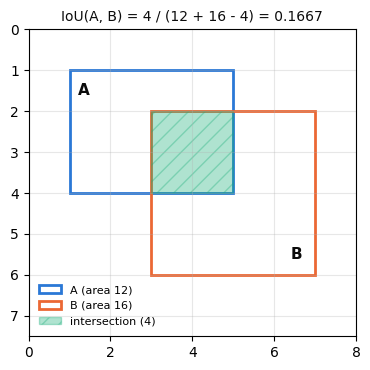

In [15]:
def iou(box_a, box_b):
    """Boxes as (x1, y1, x2, y2). Returns intersection over union."""
    ix1, iy1 = max(box_a[0], box_b[0]), max(box_a[1], box_b[1])
    ix2, iy2 = min(box_a[2], box_b[2]), min(box_a[3], box_b[3])
    inter = max(0, ix2 - ix1) * max(0, iy2 - iy1)            # max(0, .) handles boxes that do not touch
    area = lambda b: (b[2] - b[0]) * (b[3] - b[1])
    return inter / (area(box_a) + area(box_b) - inter)

A_box, B_box, C_box = (1, 1, 5, 4), (3, 2, 7, 6), (6, 0, 8, 2)
D_box, E_box = (0, 0, 4, 4), (1, 1, 3, 3)
print(f"(a) {iou(A_box, B_box):.4f} | (b) {iou(A_box, C_box):.4f} | (c) {iou(D_box, E_box):.4f}")
assert np.isclose(iou(A_box, B_box), 0.1667, atol=1e-4) and np.isclose(iou(A_box, B_box), 4 / 24)
assert iou(A_box, C_box) == 0 and iou(D_box, E_box) == 0.25
assert iou(A_box, A_box) == 1 and iou(A_box, B_box) == iou(B_box, A_box)
print("All checks passed.")

fig, ax = plt.subplots(figsize=(4.4, 3.8))
ax.add_patch(Rectangle(A_box[:2], A_box[2] - A_box[0], A_box[3] - A_box[1], fill=False, lw=2, ec=C_BLUE, label="A (area 12)"))
ax.add_patch(Rectangle(B_box[:2], B_box[2] - B_box[0], B_box[3] - B_box[1], fill=False, lw=2, ec=C_ORANGE, label="B (area 16)"))
ax.add_patch(Rectangle((3, 2), 2, 2, fc=C_AQUA, alpha=0.35, hatch="//", ec=C_AQUA, lw=1, label="intersection (4)"))
ax.text(1.2, 1.6, "A", color=INK, fontsize=11, weight="bold")
ax.text(6.4, 5.6, "B", color=INK, fontsize=11, weight="bold")
ax.set_xlim(0, 8); ax.set_ylim(7.5, 0)                       # y grows downwards, like image coordinates
ax.set_aspect("equal"); ax.grid(alpha=0.3)
ax.legend(loc="lower left", fontsize=8, frameon=False)
ax.set_title(f"IoU(A, B) = 4 / (12 + 16 - 4) = {iou(A_box, B_box):.4f}", fontsize=10, color=INK)
plt.tight_layout()
plt.show()

### Try it yourself

Compute the IoU of $(2, 2, 6, 6)$ and $(4, 4, 8, 8)$.

<details><summary>Answer</summary>

Intersection $(4, 4)$ to $(6, 6)$: $2 \cdot 2 = 4$. Union $= 16 + 16 - 4 = 28$. IoU $= 4/28 = 0.1429$.

</details>

**Exam tip:** some older code (the PASCAL VOC pixel-index convention) computes widths as $x_2 - x_1 + 1$. Check which convention your exam or library uses; this notebook uses no "+1".

## 14. Non-max suppression (NMS)

**What it is.** A detector usually fires several overlapping boxes on the same object. NMS keeps the best one and removes its duplicates.

**Analogy.** Several friends point at the same bird. You listen to the most confident friend and ignore everyone pointing at the same spot, but you still listen to a friend pointing at a *different* bird.

**How it works** (for each class separately):
1. Discard boxes whose score is below a score threshold.
2. Pick the remaining box with the highest score and **keep** it.
3. Remove every remaining box whose IoU with it is $\ge$ the IoU threshold (here 0.5).
4. Repeat steps 2-3 until no boxes are left.

### Problem

One class, IoU threshold 0.5. All scores are already above the score threshold.

| box | score | $(x_1, y_1, x_2, y_2)$ |
|---|---|---|
| B1 | 0.95 | (10, 10, 50, 50) |
| B2 | 0.85 | (12, 14, 52, 54) |
| B3 | 0.80 | (60, 60, 100, 100) |
| B4 | 0.70 | (30, 30, 70, 70) |
| B5 | 0.60 | (62, 58, 98, 104) |

Which boxes survive?

### Solution by hand

**Step 1 - sort by score:** B1, B2, B3, B4, B5.

**Step 2 - keep B1 (0.95) and compare it with the rest.** B1 has area $40 \cdot 40 = 1600$.
- B2 (area $40 \cdot 40 = 1600$): intersection $x$: 12 to 50 $= 38$, $y$: 14 to 50 $= 36$, so $I = 1{,}368$. Union $= 1600 + 1600 - 1368 = 1{,}832$. IoU $= 1368/1832 = 0.7467 \ge 0.5$: **remove**.
- B3: $\min(50, 100) - \max(10, 60) = -10 < 0$: no overlap, IoU $= 0$: stays.
- B4: intersection $x$: 30 to 50 $= 20$, $y$: 30 to 50 $= 20$, so $I = 400$. Union $= 1600 + 1600 - 400 = 2{,}800$. IoU $= 0.1429 < 0.5$: stays.
- B5: $\min(50, 98) - \max(10, 62) = -12 < 0$: IoU $= 0$: stays.

Remaining: B3, B4, B5.

**Step 3 - keep B3 (0.80) and compare.**
- B4: intersection $x$: 60 to 70 $= 10$, $y$: 60 to 70 $= 10$, so $I = 100$. Union $= 1600 + 1600 - 100 = 3{,}100$. IoU $= 0.0323$: stays.
- B5 (area $36 \cdot 46 = 1{,}656$): intersection $x$: 62 to 98 $= 36$, $y$: 60 to 100 $= 40$, so $I = 1{,}440$. Union $= 1600 + 1656 - 1440 = 1{,}816$. IoU $= 0.7930$: **remove**.

Remaining: B4.

**Step 4 - keep B4 (0.70).** Nothing is left to compare.

**Result: B1, B3, B4 survive.** B4 overlaps B1 a little, but it is a different object, so NMS keeps it: NMS removes *duplicates*, not every overlap.

  keep B1: IoU(B1, B2) = 0.7467 -> remove
  keep B1: IoU(B1, B3) = 0.0000 -> stays
  keep B1: IoU(B1, B4) = 0.1429 -> stays
  keep B1: IoU(B1, B5) = 0.0000 -> stays
  keep B3: IoU(B3, B4) = 0.0323 -> stays
  keep B3: IoU(B3, B5) = 0.7930 -> remove
kept: ['B1', 'B3', 'B4']
All checks passed.


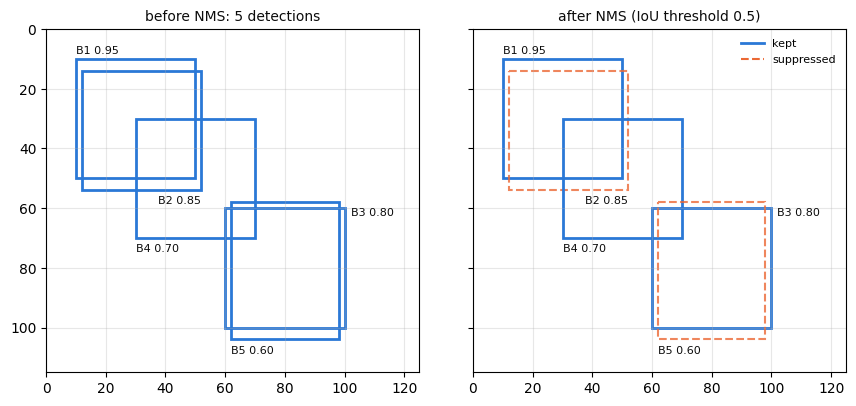

In [16]:
boxes = {"B1": (0.95, (10, 10, 50, 50)), "B2": (0.85, (12, 14, 52, 54)), "B3": (0.80, (60, 60, 100, 100)),
         "B4": (0.70, (30, 30, 70, 70)), "B5": (0.60, (62, 58, 98, 104))}

def nms(boxes, iou_threshold=0.5, verbose=True):
    remaining = sorted(boxes, key=lambda name: boxes[name][0], reverse=True)
    keep = []
    while remaining:
        best = remaining.pop(0)
        keep.append(best)
        survivors = []
        for other in remaining:
            v = iou(boxes[best][1], boxes[other][1])
            if verbose:
                print(f"  keep {best}: IoU({best}, {other}) = {v:.4f} -> {'remove' if v >= iou_threshold else 'stays'}")
            if v < iou_threshold:
                survivors.append(other)
        remaining = survivors
    return keep

kept = nms(boxes)
print("kept:", kept)
assert kept == ["B1", "B3", "B4"]
b = {name: box for name, (_, box) in boxes.items()}
assert np.isclose(iou(b["B1"], b["B2"]), 0.7467, atol=1e-4) and np.isclose(iou(b["B1"], b["B4"]), 0.1429, atol=1e-4)
assert np.isclose(iou(b["B3"], b["B4"]), 0.0323, atol=1e-4) and np.isclose(iou(b["B3"], b["B5"]), 0.7930, atol=1e-4)
assert iou(b["B1"], b["B3"]) == 0 and iou(b["B1"], b["B5"]) == 0
print("All checks passed.")

# where to write each label so labels do not collide: (x, y, horizontal alignment, vertical alignment)
label_at = {"B1": (10, 9, "left", "bottom"), "B2": (52, 56, "right", "top"), "B3": (102, 60, "left", "top"),
            "B4": (30, 72, "left", "top"), "B5": (62, 106, "left", "top")}
fig, axes = plt.subplots(1, 2, figsize=(9, 4), sharey=True)
for ax, title, show_after in [(axes[0], "before NMS: 5 detections", False), (axes[1], "after NMS (IoU threshold 0.5)", True)]:
    for name, (score, (x1, y1, x2, y2)) in boxes.items():
        is_kept = name in kept
        if show_after:
            style = dict(ec=C_BLUE, lw=2, ls="-") if is_kept else dict(ec=C_ORANGE, lw=1.5, ls="--", alpha=0.8)
        else:
            style = dict(ec=C_BLUE, lw=2, ls="-")
        ax.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, **style))
        tx, ty, ha, va = label_at[name]
        ax.text(tx, ty, f"{name} {score:.2f}", fontsize=8, color=INK, ha=ha, va=va)
    ax.set_xlim(0, 125); ax.set_ylim(115, 0)                 # y grows downwards
    ax.set_aspect("equal"); ax.set_title(title, fontsize=10, color=INK); ax.grid(alpha=0.3)
axes[1].plot([], [], color=C_BLUE, lw=2, label="kept")
axes[1].plot([], [], color=C_ORANGE, lw=1.5, ls="--", label="suppressed")
axes[1].legend(loc="upper right", fontsize=8, frameon=False)
plt.tight_layout()
plt.show()

### Try it yourself

Rerun NMS on the same 5 boxes with an IoU threshold of **0.1**. Which boxes survive now?

<details><summary>Answer</summary>

Keep B1; remove B2 (0.7467) and also B4 (0.1429 ≥ 0.1); B3 and B5 stay. Keep B3; remove B5 (0.7930). Result: **B1, B3**. A threshold that is too low merges nearby *different* objects (bad for crowds); one that is too high leaves duplicates.

</details>

**Exam tip:** NMS runs separately for each class. A "cat" box never suppresses a "dog" box.

## 15. Anchor boxes and the YOLO output volume

**What it is.** Anchor boxes are a few preset box shapes in every grid cell. Each object is assigned to the grid cell that contains its **centre**, and to the anchor whose **shape** matches it best (highest IoU). This lets one cell detect several objects of different shapes.

**Analogy.** A car park with spaces for cars and for motorbikes: each vehicle parks in the space whose shape fits it best.

**How it works.** To compare shapes only, line up the centres, so
$$\text{IoU}_{shape} = \frac{\min(w_1, w_2)\cdot\min(h_1, h_2)}{w_1 h_1 + w_2 h_2 - \min(w_1, w_2)\cdot\min(h_1, h_2)}$$
A YOLO-style output (YOLOv2 onwards) has shape $S \times S \times B \times (5 + C)$: an $S \times S$ grid, $B$ anchors per cell, and for each anchor $p_c, b_x, b_y, b_h, b_w$ plus $C$ class scores.

### Problem

A 300×300 image is split into a 3×3 grid (each cell 100×100 px). Anchors (width × height): A1 = 40×80 (tall), A2 = 80×40 (wide), A3 = 60×60 (square). Classes: 1 = person, 2 = car, 3 = bike.
- A person: centre (130, 150), 36 wide × 72 tall.
- A car: centre (170, 140), 90 wide × 45 tall.

(a) Which grid cell and which anchor gets each object?

(b) Write the target for that cell ($b_x, b_y$ relative to the cell's top-left corner and $b_h, b_w$ in cell units, all divided by the cell size 100).

(c) Output volume size for: $S = 3, B = 2, C = 3$; $S = 13, B = 5, C = 20$ (YOLOv2 on PASCAL VOC); YOLOv1 with $S = 7, B = 2, C = 20$, whose format is $S \times S \times (5B + C)$; and YOLOv3 on 416×416 inputs: three scales with $S = 13, 26, 52$, $B = 3$, $C = 80$ (total number of predicted boxes).

### Solution by hand

**Step 1 - grid cells.** Person centre (130, 150): column $\lfloor 130/100 \rfloor = 1$, row $\lfloor 150/100 \rfloor = 1$. Car centre (170, 140): column 1, row 1. **The same cell**, which is exactly the situation anchors are for.

**Step 2 - anchor IoUs.** Person (36×72, area 2,592):
- A1 (40×80, area 3,200): $I = \min(36, 40) \cdot \min(72, 80) = 36 \cdot 72 = 2{,}592$; $U = 2592 + 3200 - 2592 = 3{,}200$; IoU $= 0.81$
- A2 (80×40, area 3,200): $I = 36 \cdot 40 = 1{,}440$; $U = 2592 + 3200 - 1440 = 4{,}352$; IoU $= 0.3309$
- A3 (60×60, area 3,600): $I = 36 \cdot 60 = 2{,}160$; $U = 2592 + 3600 - 2160 = 4{,}032$; IoU $= 0.5357$

The person goes to **A1**. Car (90×45, area 4,050):
- A1: $I = 40 \cdot 45 = 1{,}800$; $U = 4050 + 3200 - 1800 = 5{,}450$; IoU $= 0.3303$
- A2: $I = 80 \cdot 40 = 3{,}200$; $U = 4050 + 3200 - 3200 = 4{,}050$; IoU $= 0.7901$
- A3: $I = 60 \cdot 45 = 2{,}700$; $U = 4050 + 3600 - 2700 = 4{,}950$; IoU $= 0.5455$

The car goes to **A2**.

**Step 3 - the cell's target (b).** The cell's top-left corner is (100, 100).
- person: $b_x = (130 - 100)/100 = 0.30$, $b_y = (150 - 100)/100 = 0.50$, $b_h = 72/100 = 0.72$, $b_w = 36/100 = 0.36$
- car: $b_x = 0.70$, $b_y = 0.40$, $b_h = 0.45$, $b_w = 0.90$

$$y_{cell} = [\underbrace{1, 0.30, 0.50, 0.72, 0.36, 1, 0, 0}_{\text{A1: person}} \mid \underbrace{1, 0.70, 0.40, 0.45, 0.90, 0, 1, 0}_{\text{A2: car}} \mid \underbrace{0, ?, ?, ?, ?, ?, ?, ?}_{\text{A3: empty}}]$$
That is $3 \times 8 = 24$ numbers for this cell.

**Step 4 - output sizes (c).**
- $3 \times 3 \times 2 \times (5 + 3) = 3 \times 3 \times 16$, i.e. $144$ numbers
- $13 \times 13 \times 5 \times (5 + 20) = 13 \times 13 \times 125$, i.e. $21{,}125$ numbers
- YOLOv1: $7 \times 7 \times (5 \cdot 2 + 20) = 7 \times 7 \times 30$, i.e. $1{,}470$ numbers (the class scores are shared by the boxes in a cell)
- YOLOv3: $(13^2 + 26^2 + 52^2) \times 3 = (169 + 676 + 2{,}704) \times 3 = 3{,}549 \times 3 = 10{,}647$ boxes, each with $5 + 80 = 85$ numbers (for example $13 \times 13 \times 255$ at the coarsest scale)

In [17]:
def shape_iou(wh_a, wh_b):
    """IoU of two boxes given only (width, height), with their centres lined up."""
    inter = min(wh_a[0], wh_b[0]) * min(wh_a[1], wh_b[1])
    return inter / (wh_a[0] * wh_a[1] + wh_b[0] * wh_b[1] - inter)

anchors = {"A1": (40, 80), "A2": (80, 40), "A3": (60, 60)}
objects = {"person": ((130, 150), (36, 72)), "car": ((170, 140), (90, 45))}
cell = 100
for name, ((cx, cy), wh) in objects.items():
    ious = {a: shape_iou(wh, a_wh) for a, a_wh in anchors.items()}
    best = max(ious, key=ious.get)
    row, col = cy // cell, cx // cell
    print(f"{name}: cell (row {row}, col {col}) | IoUs " + ", ".join(f"{a}={v:.4f}" for a, v in ious.items()) + f" -> {best}")
    assert (row, col) == (1, 1)
    if name == "person":
        assert best == "A1" and np.allclose(list(ious.values()), [0.81, 0.3309, 0.5357], atol=1e-4)
    else:
        assert best == "A2" and np.allclose(list(ious.values()), [0.3303, 0.7901, 0.5455], atol=1e-4)

person = [1, (130 - 100) / cell, (150 - 100) / cell, 72 / cell, 36 / cell, 1, 0, 0]
car = [1, (170 - 100) / cell, (140 - 100) / cell, 45 / cell, 90 / cell, 0, 1, 0]
y_cell = np.array(person + car + [0] + [np.nan] * 7)
print("(b) target for cell (1, 1):", y_cell)
assert np.allclose(y_cell[:16], [1, 0.3, 0.5, 0.72, 0.36, 1, 0, 0, 1, 0.7, 0.4, 0.45, 0.9, 0, 1, 0]) and len(y_cell) == 24

yolo = lambda S, B, C: S * S * B * (5 + C)
sizes = (yolo(3, 2, 3), yolo(13, 5, 20), 7 * 7 * (5 * 2 + 20), sum(S * S * 3 for S in (13, 26, 52)))
print("(c)", sizes)
assert sizes == (144, 21_125, 1_470, 10_647) and 3 * (5 + 80) == 255
print("All checks passed.")

person: cell (row 1, col 1) | IoUs A1=0.8100, A2=0.3309, A3=0.5357 -> A1
car: cell (row 1, col 1) | IoUs A1=0.3303, A2=0.7901, A3=0.5455 -> A2
(b) target for cell (1, 1): [1.   0.3  0.5  0.72 0.36 1.   0.   0.   1.   0.7  0.4  0.45 0.9  0.
 1.   0.   0.    nan  nan  nan  nan  nan  nan  nan]
(c) (144, 21125, 1470, 10647)
All checks passed.


### Try it yourself

(a) What is the output volume for $S = 4$, $B = 3$, $C = 2$? (b) With the same three anchors, which anchor gets an object that is 60 wide × 50 tall?

<details><summary>Answer</summary>

(a) $4 \times 4 \times 3 \times 7 = 4 \times 4 \times 21$, i.e. 336 numbers.
(b) A1: $I = 40 \cdot 50 = 2000$, $U = 3000 + 3200 - 2000 = 4200$, IoU $= 0.4762$. A2: $I = 60 \cdot 40 = 2400$, $U = 3000 + 3200 - 2400 = 3800$, IoU $= 0.6316$. A3: $I = 60 \cdot 50 = 3000$, $U = 3000 + 3600 - 3000 = 3600$, IoU $= 0.8333$. So **A3**.

</details>

**Exam tip:** anchors fail when two objects in the same cell want the **same** anchor; a finer grid (larger $S$) makes that rare.

## 16. Detection evaluation: precision, recall, AP and mAP

**What it is.** A detection is a **true positive (TP)** if its IoU with a ground-truth box that has not been matched yet is $\ge 0.5$; otherwise it is a **false positive (FP)**. Then
$$\text{precision} = \frac{TP}{TP + FP}, \qquad \text{recall} = \frac{TP}{\text{number of ground-truth objects}}$$
**AP** (average precision) summarizes the precision-recall curve of one class in one number; **mAP** is the mean of the APs over all classes.

**Analogy.** Fishing with a net: recall is the share of the lake's fish you caught; precision is the share of your catch that is fish rather than old boots.

**How it works.** Sort detections by confidence and go down the list, updating cumulative precision and recall. The **interpolated precision** $p_{interp}(r)$ is the best precision at any recall $\ge r$ (look to the right).
- **All-point AP** (PASCAL VOC since 2010, similar to COCO): $\text{AP} = \sum_k (R_k - R_{k-1})\, p_{interp}(R_k)$, the area under the interpolated curve.
- **11-point AP** (VOC 2007): $\text{AP} = \frac{1}{11}\sum_{r \in \{0, 0.1, \ldots, 1\}} p_{interp}(r)$, with $p_{interp}(r) = 0$ if recall $r$ is never reached.

### Problem

Class "cat" has 4 ground-truth boxes, GT1 to GT4. Its detections, sorted by confidence, with each one's best IoU:

| rank | confidence | best IoU | with |
|---|---|---|---|
| 1 | 0.95 | 0.82 | GT1 |
| 2 | 0.88 | 0.40 | GT2 |
| 3 | 0.80 | 0.71 | GT2 |
| 4 | 0.71 | 0.65 | GT1 |
| 5 | 0.60 | 0.55 | GT3 |
| 6 | 0.45 | 0.00 | none |

Class "dog" has 2 ground-truth boxes; its detections, in confidence order, are TP, FP, TP.

(a) Mark each cat detection TP or FP. (b) Make the precision/recall table. (c) Compute the all-point AP and the 11-point AP for cat. (d) Compute the AP for dog and the mAP over the two classes.

### Solution by hand

**Step 1 - TP or FP (a).** Rank 1: TP (0.82 ≥ 0.5, GT1 is free). Rank 2: FP (0.40 < 0.5). Rank 3: TP (matches GT2). Rank 4: **FP**, because GT1 is already matched (a duplicate). Rank 5: TP (GT3). Rank 6: FP. GT4 is never found.

**Step 2 - precision and recall (b).**

| rank | TP/FP | cum. TP | cum. FP | precision | recall |
|---|---|---|---|---|---|
| 1 | TP | 1 | 0 | 1/1 = 1.0000 | 1/4 = 0.25 |
| 2 | FP | 1 | 1 | 1/2 = 0.5000 | 0.25 |
| 3 | TP | 2 | 1 | 2/3 = 0.6667 | 2/4 = 0.50 |
| 4 | FP | 2 | 2 | 2/4 = 0.5000 | 0.50 |
| 5 | TP | 3 | 2 | 3/5 = 0.6000 | 3/4 = 0.75 |
| 6 | FP | 3 | 3 | 3/6 = 0.5000 | 0.75 |

**Step 3 - interpolated precision.** At recall 0.25: max(1, 0.5, 0.6667, 0.5, 0.6, 0.5) $= 1.0$. At 0.50: max(0.6667, 0.5, 0.6, 0.5) $= 0.6667$. At 0.75: max(0.6, 0.5) $= 0.6$.

**Step 4 - all-point AP (c).**
$\text{AP} = (0.25 - 0)(1.0) + (0.50 - 0.25)(0.6667) + (0.75 - 0.50)(0.6) = 0.25 + 0.1667 + 0.15 = 0.5667$.
Recall never reaches 1, so the area between recall 0.75 and 1 is 0.

**Step 5 - 11-point AP (c).**
- $r = 0, 0.1, 0.2$: $p_{interp} = 1.0$ (3 points)
- $r = 0.3, 0.4, 0.5$: $0.6667$ (3 points)
- $r = 0.6, 0.7$: $0.6$ (2 points)
- $r = 0.8, 0.9, 1.0$: $0$ (no detection reaches these recalls; 3 points)

$\text{AP}_{11} = (3 \times 1.0 + 3 \times 0.6667 + 2 \times 0.6 + 3 \times 0)/11 = (3 + 2 + 1.2)/11 = 6.2/11 = 0.5636$

**Step 6 - dog and mAP (d).** Dog: precision $1/1 = 1$, $1/2 = 0.5$, $2/3 = 0.6667$; recall $0.5, 0.5, 1.0$. Interpolated: 1.0 at recall 0.5, 0.6667 at recall 1.0.
All-point $\text{AP}_{dog} = 0.5 \times 1.0 + 0.5 \times 0.6667 = 0.8333$. (11-point: $(6 \times 1 + 5 \times 0.6667)/11 = 9.3333/11 = 0.8485$.)

$$\text{mAP} = \frac{0.5667 + 0.8333}{2} = 0.7000 \qquad (\text{11-point: } (0.563636 + 0.848485)/2 = 0.7061)$$

COCO's headline metric "mAP@[.5:.95]" also averages AP over the IoU thresholds 0.50, 0.55, ..., 0.95 (and uses 101 recall points).

(a) cat TP flags: [1, 0, 1, 0, 1, 0]
(b) precision: [1.     0.5    0.6667 0.5    0.6    0.5   ] 
    recall:    [0.25 0.25 0.5  0.5  0.75 0.75]
(c) cat AP all-point = 0.5667, 11-point = 0.5636
(d) dog AP all-point = 0.8333, 11-point = 0.8485 | mAP = 0.7000 (11-point 0.7061)
All checks passed.


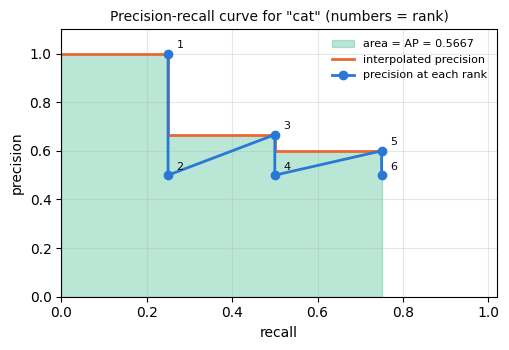

In [18]:
def match_detections(dets, iou_threshold=0.5):
    """dets: list of (confidence, best IoU, ground-truth id) sorted by confidence. Each GT can be matched once."""
    matched, flags = set(), []
    for conf, best_iou, gt in dets:
        is_tp = gt is not None and best_iou >= iou_threshold and gt not in matched
        if is_tp:
            matched.add(gt)
        flags.append(int(is_tp))
    return flags

def precision_recall(tp_flags, n_gt):
    tp = np.cumsum(tp_flags)
    fp = np.cumsum(1 - np.array(tp_flags))
    return tp / (tp + fp), tp / n_gt

def ap_all_points(precision, recall):
    p_interp = np.array([precision[k:].max() for k in range(len(precision))])   # best precision to the right
    previous_recall = np.concatenate([[0], recall[:-1]])
    return np.sum((recall - previous_recall) * p_interp)

def ap_11_points(precision, recall):
    points = [precision[recall >= r - 1e-12].max() if np.any(recall >= r - 1e-12) else 0.0
              for r in np.linspace(0, 1, 11)]
    return np.mean(points)

cat_dets = [(0.95, 0.82, "GT1"), (0.88, 0.40, "GT2"), (0.80, 0.71, "GT2"),
            (0.71, 0.65, "GT1"), (0.60, 0.55, "GT3"), (0.45, 0.00, None)]
cat_flags = match_detections(cat_dets)
P_cat, R_cat = precision_recall(cat_flags, n_gt=4)
P_dog, R_dog = precision_recall([1, 0, 1], n_gt=2)
ap_cat, ap11_cat = ap_all_points(P_cat, R_cat), ap_11_points(P_cat, R_cat)
ap_dog, ap11_dog = ap_all_points(P_dog, R_dog), ap_11_points(P_dog, R_dog)

print("(a) cat TP flags:", cat_flags)
print("(b) precision:", P_cat, "\n    recall:   ", R_cat)
print(f"(c) cat AP all-point = {ap_cat:.4f}, 11-point = {ap11_cat:.4f}")
print(f"(d) dog AP all-point = {ap_dog:.4f}, 11-point = {ap11_dog:.4f} | mAP = {(ap_cat + ap_dog) / 2:.4f}"
      f" (11-point {(ap11_cat + ap11_dog) / 2:.4f})")

assert cat_flags == [1, 0, 1, 0, 1, 0]
assert np.allclose(P_cat, [1, 0.5, 0.6667, 0.5, 0.6, 0.5], atol=1e-4) and np.allclose(R_cat, [0.25, 0.25, 0.5, 0.5, 0.75, 0.75])
assert np.isclose(ap_cat, 0.5667, atol=1e-4) and np.isclose(ap11_cat, 0.5636, atol=1e-4)
assert np.isclose(ap_dog, 0.8333, atol=1e-4) and np.isclose(ap11_dog, 0.8485, atol=1e-4)
assert np.isclose((ap_cat + ap_dog) / 2, 0.7) and np.isclose((ap11_cat + ap11_dog) / 2, 0.7061, atol=1e-4)
print("All checks passed.")

# Precision-recall curve for "cat": raw points and the interpolated envelope whose area is the AP
p_interp = np.array([P_cat[k:].max() for k in range(len(P_cat))])
xs, ys, prev_r = [], [], 0.0
for r, p in zip(R_cat, p_interp):
    if r > prev_r:                                           # one rectangle per recall step
        xs += [prev_r, r]; ys += [p, p]; prev_r = r
fig, ax = plt.subplots(figsize=(5.2, 3.6))
ax.fill_between(xs, ys, color=C_AQUA, alpha=0.3, label=f"area = AP = {ap_cat:.4f}")
ax.plot(xs, ys, color=C_ORANGE, lw=2, label="interpolated precision")
ax.plot(R_cat, P_cat, "o-", color=C_BLUE, lw=2, ms=6, label="precision at each rank")
for k, (r, p) in enumerate(zip(R_cat, P_cat), start=1):
    ax.annotate(str(k), (r, p), textcoords="offset points", xytext=(6, 4), fontsize=8, color=INK)
ax.set_xlim(0, 1.02); ax.set_ylim(0, 1.1)
ax.set_xlabel("recall"); ax.set_ylabel("precision")
ax.set_title('Precision-recall curve for "cat" (numbers = rank)', fontsize=10, color=INK)
ax.grid(alpha=0.3); ax.legend(loc="upper right", fontsize=8, frameon=False)
plt.tight_layout()
plt.show()

### Try it yourself

A class has 3 ground-truth objects. The detections, in confidence order, are TP, TP, FP, TP. Compute the all-point AP (and, as a bonus, the 11-point AP).

<details><summary>Answer</summary>

Precision: $1, 1, 0.6667, 0.75$; recall: $0.3333, 0.6667, 0.6667, 1.0$. Interpolated precision: 1 at recall 1/3, 1 at 2/3, 0.75 at 1.
All-point AP $= \frac{1}{3}(1) + \frac{1}{3}(1) + \frac{1}{3}(0.75) = 0.9167$.
11-point: $r = 0 \ldots 0.6$ give 1 (7 points), $r = 0.7 \ldots 1.0$ give 0.75 (4 points): $(7 + 3)/11 = 0.9091$.

</details>

**Common mistake:** counting a second detection of an already-matched object as a TP. Each ground-truth box can be matched only once; the duplicate is an FP (rank 4 above).

## 17. Segmentation metrics: pixel accuracy, IoU (Jaccard) and Dice

**What it is.** A segmentation model labels every pixel. We compare the predicted mask $P$ with the true mask $G$ pixel by pixel.

**Analogy.** Checking a colouring-book page: which squares did you colour that should be coloured, and which did you miss or colour by mistake?

**How it works.** Count TP (both 1), FP (predicted 1, truly 0), FN (predicted 0, truly 1) and TN (both 0) over the $N$ pixels.
$$\text{pixel accuracy} = \frac{TP + TN}{N}, \qquad \text{IoU} = \frac{TP}{TP + FP + FN}, \qquad \text{Dice} = \frac{2\,TP}{2\,TP + FP + FN}, \qquad \text{Dice} = \frac{2\,\text{IoU}}{1 + \text{IoU}}$$

### Problem

$$G = \begin{bmatrix}0&1&1&0\\0&1&1&0\\0&1&1&1\\0&0&0&0\end{bmatrix} \text{ (truth)}, \qquad
P = \begin{bmatrix}0&1&1&1\\0&1&1&0\\0&0&1&1\\0&0&0&0\end{bmatrix} \text{ (prediction)}$$

(a) Count TP, FP, FN and TN.

(b) Compute pixel accuracy, IoU and Dice, and check $\text{Dice} = 2\,\text{IoU}/(1 + \text{IoU})$.

(c) Compute the IoU of the **background** class (0) and the mean IoU (mIoU) over the 2 classes.

(d) A lazy model predicts all zeros. What are its pixel accuracy, IoU and Dice?

### Solution by hand

**Step 1 - counts (a).**
- TP (both 1): (0,1), (0,2), (1,1), (1,2), (2,2), (2,3), so $TP = 6$
- FP (predicted 1, truly 0): (0,3), so $FP = 1$
- FN (predicted 0, truly 1): (2,1), so $FN = 1$
- TN: $16 - 6 - 1 - 1 = 8$

**Step 2 - metrics (b).**
- pixel accuracy $= (6 + 8)/16 = 14/16 = 0.875$
- IoU $= 6/(6 + 1 + 1) = 6/8 = 0.75$
- Dice $= 2(6)/(2(6) + 1 + 1) = 12/14 = 0.8571$
- check: $2(0.75)/(1 + 0.75) = 1.5/1.75 = 0.8571 \;\checkmark$

**Step 3 - background IoU and mIoU (c).** Treat 0 as the positive class: TP becomes 8 (the old TN), and FP and FN swap roles (1 each). Background IoU $= 8/(8 + 1 + 1) = 0.8$. mIoU $= (0.75 + 0.8)/2 = 0.775$.

**Step 4 - the lazy model (d).** TP = 0, FP = 0, FN = 7, TN = 9: accuracy $= 9/16 = 0.5625$, IoU $= 0/7 = 0$, Dice $= 0$. For a tiny object, say 1 pixel out of 16, "all zeros" would score $15/16 = 0.9375$ accuracy with IoU 0. That is why segmentation is reported with IoU or Dice, not pixel accuracy.

In [19]:
def seg_metrics(G, P):
    tp = int(np.sum((G == 1) & (P == 1))); fp = int(np.sum((G == 0) & (P == 1)))
    fn = int(np.sum((G == 1) & (P == 0))); tn = int(np.sum((G == 0) & (P == 0)))
    acc = (tp + tn) / G.size
    iou_v = tp / (tp + fp + fn) if tp + fp + fn else 1.0
    dice = 2 * tp / (2 * tp + fp + fn) if tp + fp + fn else 1.0
    return tp, fp, fn, tn, acc, iou_v, dice

G = np.array([[0, 1, 1, 0], [0, 1, 1, 0], [0, 1, 1, 1], [0, 0, 0, 0]])
P = np.array([[0, 1, 1, 1], [0, 1, 1, 0], [0, 0, 1, 1], [0, 0, 0, 0]])
tp, fp, fn, tn, acc, iou_obj, dice = seg_metrics(G, P)
iou_bg = seg_metrics(1 - G, 1 - P)[5]
print(f"(a) TP={tp} FP={fp} FN={fn} TN={tn}")
print(f"(b) accuracy={acc:.4f} IoU={iou_obj:.4f} Dice={dice:.4f} | 2IoU/(1+IoU)={2 * iou_obj / (1 + iou_obj):.4f}")
print(f"(c) background IoU={iou_bg:.4f} mIoU={(iou_obj + iou_bg) / 2:.4f}")
lazy = seg_metrics(G, np.zeros_like(G))
print(f"(d) all-zeros model: accuracy={lazy[4]:.4f} IoU={lazy[5]:.4f} Dice={lazy[6]:.4f}")

assert (tp, fp, fn, tn) == (6, 1, 1, 8)
assert acc == 0.875 and iou_obj == 0.75 and np.isclose(dice, 0.8571, atol=1e-4)
assert np.isclose(dice, 2 * iou_obj / (1 + iou_obj))
assert np.isclose(iou_bg, 0.8) and np.isclose((iou_obj + iou_bg) / 2, 0.775)
assert lazy[4] == 0.5625 and lazy[5] == 0 and lazy[6] == 0
print("All checks passed.")

(a) TP=6 FP=1 FN=1 TN=8
(b) accuracy=0.8750 IoU=0.7500 Dice=0.8571 | 2IoU/(1+IoU)=0.8571
(c) background IoU=0.8000 mIoU=0.7750
(d) all-zeros model: accuracy=0.5625 IoU=0.0000 Dice=0.0000
All checks passed.


### Try it yourself

$G$ has ones at (0,0), (0,1), (1,0), (1,1) and zeros elsewhere (4×4). $P$ has ones at (0,0), (0,1), (0,2), (1,0). Compute pixel accuracy, IoU and Dice.

<details><summary>Answer</summary>

TP = 3, FP = 1 at (0,2), FN = 1 at (1,1), TN = 11. Accuracy $= 14/16 = 0.875$, IoU $= 3/5 = 0.6$, Dice $= 6/8 = 0.75$ (check: $1.2/1.6 = 0.75$).

</details>

**Exam tip:** Dice is always $\ge$ IoU (they are equal only at 0 and at 1), so never compare a Dice score from one paper with an IoU score from another.

## 18. Face verification and triplet loss

**What it is.** A network maps each face photo $x$ to an embedding vector $f(x)$. **Verification** ("is this the claimed person?") compares two embeddings: same person if
$$d = \lVert f(x_1) - f(x_2) \rVert^2 < \tau.$$
Training uses the **triplet loss** on an anchor $A$, a positive $P$ (same person) and a negative $N$ (different person):
$$L(A, P, N) = \max\left(\lVert f(A) - f(P) \rVert^2 - \lVert f(A) - f(N) \rVert^2 + \alpha,\; 0\right)$$

**Analogy.** A "face fingerprint" on a map: photos of the same person should land in the same neighbourhood, and the margin $\alpha$ is a required safety gap between neighbourhoods.

**How it works.** Real embeddings have 128 or more dimensions; here they are 2-D so you can calculate by hand. Distances are squared Euclidean distances.

### Problem

(a) Asha's stored embedding is $[0.6, 0.8]$. Two new photos give $f(x_1) = [0.5, 0.9]$ and $f(x_2) = [0.9, 0.1]$. With $\tau = 0.5$, accept or reject each?

(b) $\alpha = 0.2$, anchor $f(A) = [1.0, 0.0]$, positive $f(P) = [0.8, 0.3]$. Compute the triplet loss for each negative: $N_1 = [0.6, -0.2]$, $N_2 = [-0.2, 1.0]$, $N_3 = [0.9, 0.2]$. What is the total, and which triplets are "easy" and "hard"?

### Solution by hand

**Step 1 - verification (a).**
- $d_1 = (0.5 - 0.6)^2 + (0.9 - 0.8)^2 = 0.01 + 0.01 = 0.02 < 0.5$: **accept** (same person)
- $d_2 = (0.9 - 0.6)^2 + (0.1 - 0.8)^2 = 0.09 + 0.49 = 0.58 > 0.5$: **reject**

**Step 2 - anchor-positive distance (b).** $d(A, P) = (1.0 - 0.8)^2 + (0 - 0.3)^2 = 0.04 + 0.09 = 0.13$.

**Step 3 - each negative.**
- $N_1$: $d = (1.0 - 0.6)^2 + (0 + 0.2)^2 = 0.16 + 0.04 = 0.20$; $L = \max(0.13 - 0.20 + 0.2, 0) = 0.13$. *Semi-hard*: $N_1$ is farther than $P$, but not by the margin.
- $N_2$: $d = 1.2^2 + 1.0^2 = 1.44 + 1.0 = 2.44$; $L = \max(0.13 - 2.44 + 0.2, 0) = \max(-2.11, 0) = 0$. *Easy*: it teaches the network nothing.
- $N_3$: $d = 0.1^2 + 0.2^2 = 0.01 + 0.04 = 0.05$; $L = 0.13 - 0.05 + 0.2 = 0.28$. *Hard*: the negative is **closer** than the positive.

**Step 4 - total.** $0.13 + 0 + 0.28 = 0.41$. Random triplets are mostly easy (loss 0, no learning), so training picks hard or semi-hard triplets on purpose.

In [20]:
sq_dist = lambda u, v: float(np.sum((np.asarray(u) - np.asarray(v)) ** 2))

def triplet_loss(a, p, n, alpha):
    return max(sq_dist(a, p) - sq_dist(a, n) + alpha, 0.0)

asha = [0.6, 0.8]
d1, d2 = sq_dist([0.5, 0.9], asha), sq_dist([0.9, 0.1], asha)
print(f"(a) d1={d1:.4f} -> {'accept' if d1 < 0.5 else 'reject'} | d2={d2:.4f} -> {'accept' if d2 < 0.5 else 'reject'}")
assert np.isclose(d1, 0.02) and np.isclose(d2, 0.58) and d1 < 0.5 < d2

A_emb, P_emb = [1.0, 0.0], [0.8, 0.3]
negatives = {"N1": [0.6, -0.2], "N2": [-0.2, 1.0], "N3": [0.9, 0.2]}
losses = {k: triplet_loss(A_emb, P_emb, n, alpha=0.2) for k, n in negatives.items()}
print(f"(b) d(A,P)={sq_dist(A_emb, P_emb):.4f} | " + ", ".join(
    f"{k}: d(A,N)={sq_dist(A_emb, n):.4f} loss={losses[k]:.4f}" for k, n in negatives.items()))
print(f"    total = {sum(losses.values()):.4f}")
assert np.isclose(sq_dist(A_emb, P_emb), 0.13)
assert np.allclose([losses["N1"], losses["N2"], losses["N3"]], [0.13, 0.0, 0.28]) and np.isclose(sum(losses.values()), 0.41)
print("All checks passed.")

(a) d1=0.0200 -> accept | d2=0.5800 -> reject
(b) d(A,P)=0.1300 | N1: d(A,N)=0.2000 loss=0.1300, N2: d(A,N)=2.4400 loss=0.0000, N3: d(A,N)=0.0500 loss=0.2800
    total = 0.4100
All checks passed.


### Try it yourself

$f(A) = [0, 1]$, $f(P) = [0.2, 0.8]$, $f(N) = [0.5, 0.5]$. Compute the triplet loss with $\alpha = 0.1$ and with $\alpha = 0.5$.

<details><summary>Answer</summary>

$d(A, P) = 0.04 + 0.04 = 0.08$, $d(A, N) = 0.25 + 0.25 = 0.5$. With $\alpha = 0.1$: $\max(0.08 - 0.5 + 0.1, 0) = \max(-0.32, 0) = 0$. With $\alpha = 0.5$: $\max(0.08 - 0.5 + 0.5, 0) = 0.08$. A bigger margin turns an "easy" triplet into a useful one.

</details>

**Exam tip:** without the margin $\alpha$, the network could map every face to the same point: all distances 0, loss 0, and nothing learned. The margin rules out this trivial solution.

## 19. Neural style transfer: Gram matrix, style cost and content cost

**What it is.** Neural style transfer creates an image $G$ with the **content** of an image $C$ and the **style** of an image $S$. The content cost compares a layer's activations directly; the style cost compares their **Gram matrices**, which measure how strongly pairs of channels fire together.

**Analogy.** Content is *what* is in the picture and *where*. Style is *which brush strokes and colours tend to appear together*, wherever they are.

**How it works.** Unroll a layer's activations into a matrix $F$ with $n_C$ rows (channels) and $n_H n_W$ columns (positions). Then
$$G = F F^T,\; \text{i.e. } G_{kk'} = \sum_{\text{positions}} F_{k} F_{k'}$$
$$J_{style} = \frac{1}{4\, n_C^2\, (n_H n_W)^2} \sum_{k, k'} \left(G^{S}_{kk'} - G^{G}_{kk'}\right)^2, \qquad J_{content} = \frac{1}{2} \sum \left(a^{C} - a^{G}\right)^2, \qquad J = \alpha J_{content} + \beta J_{style}$$
(These are the normalizations of the original paper by Gatys et al.; see the exam tip.)

### Problem

A layer has $n_C = 2$ channels and $n_H \times n_W = 2 \times 2 = 4$ positions:
$$F_S = \begin{bmatrix}1&0&2&1\\0&1&1&2\end{bmatrix} \text{ (style)}, \quad
F_G = \begin{bmatrix}1&1&1&0\\1&0&1&1\end{bmatrix} \text{ (generated)}, \quad
F_C = \begin{bmatrix}2&0&1&1\\1&1&0&2\end{bmatrix} \text{ (content)}$$

(a) Compute the Gram matrices of $S$ and $G$. (b) Compute $J_{style}$. (c) Compute $J_{content}$. (d) Compute $J$ with $\alpha = 1$, $\beta = 10$.

### Solution by hand

**Step 1 - Gram matrices (a).** Each entry is a dot product of two rows.
- $G^S_{11} = 1 \cdot 1 + 0 \cdot 0 + 2 \cdot 2 + 1 \cdot 1 = 6$; $\;G^S_{12} = 1 \cdot 0 + 0 \cdot 1 + 2 \cdot 1 + 1 \cdot 2 = 4$; $\;G^S_{22} = 0 + 1 + 1 + 4 = 6$
- $G^G_{11} = 1 + 1 + 1 + 0 = 3$; $\;G^G_{12} = 1 \cdot 1 + 1 \cdot 0 + 1 \cdot 1 + 0 \cdot 1 = 2$; $\;G^G_{22} = 1 + 0 + 1 + 1 = 3$

$$G^S = \begin{bmatrix}6&4\\4&6\end{bmatrix}, \qquad G^G = \begin{bmatrix}3&2\\2&3\end{bmatrix} \qquad (\text{symmetric: } G_{21} = G_{12})$$

**Step 2 - style cost (b).** Differences $G^S - G^G = \begin{bmatrix}3&2\\2&3\end{bmatrix}$; sum of squares $= 9 + 4 + 4 + 9 = 26$.
Normalizer: $4 \cdot n_C^2 \cdot (n_H n_W)^2 = 4 \cdot 4 \cdot 16 = 256$. $\;J_{style} = 26/256 = 0.1016$ (exactly 0.1015625).

**Step 3 - content cost (c).** $a^C - a^G = F_C - F_G = \begin{bmatrix}1&-1&0&1\\0&1&-1&1\end{bmatrix}$; sum of squares $= 1 + 1 + 0 + 1 + 0 + 1 + 1 + 1 = 6$. $\;J_{content} = \frac{1}{2} \cdot 6 = 3.0$.

**Step 4 - total (d).** $J = 1 \cdot 3.0 + 10 \cdot 0.1015625 = 3.0 + 1.015625 = 4.0156$.

**Why the Gram matrix captures style.** $G$ sums over positions, so it does not care **where** things are: shuffling the 4 columns of $F$ gives the same $G$ (the code checks this). It keeps "what goes with what" (texture) and throws away the layout (content).

In [21]:
F_S = np.array([[1, 0, 2, 1], [0, 1, 1, 2]], dtype=float)
F_G = np.array([[1, 1, 1, 0], [1, 0, 1, 1]], dtype=float)
F_C = np.array([[2, 0, 1, 1], [1, 1, 0, 2]], dtype=float)
n_C, n_HW = F_S.shape

gram = lambda F: F @ F.T
G_S, G_G = gram(F_S), gram(F_G)
J_style = np.sum((G_S - G_G) ** 2) / (4 * n_C**2 * n_HW**2)
J_content = 0.5 * np.sum((F_C - F_G) ** 2)
J_total = 1 * J_content + 10 * J_style
print("(a) G_S =\n", G_S, "\n    G_G =\n", G_G)
print(f"(b) J_style = {J_style:.4f} | (c) J_content = {J_content:.4f} | (d) J = {J_total:.4f}")

assert np.array_equal(G_S, [[6, 4], [4, 6]]) and np.array_equal(G_G, [[3, 2], [2, 3]])
assert J_style == 26 / 256 and np.isclose(J_style, 0.1016, atol=1e-4)
assert J_content == 3.0 and np.isclose(J_total, 4.0156, atol=1e-4)
shuffled = F_S[:, [2, 0, 3, 1]]                       # move the positions around
assert np.array_equal(gram(shuffled), G_S)             # same Gram matrix: style ignores layout
print("All checks passed.")

(a) G_S =
 [[6. 4.]
 [4. 6.]] 
    G_G =
 [[3. 2.]
 [2. 3.]]
(b) J_style = 0.1016 | (c) J_content = 3.0000 | (d) J = 4.0156
All checks passed.


### Try it yourself

Compute the Gram matrix of $F = \begin{bmatrix}1&2&0&1\\2&0&1&1\end{bmatrix}$.

<details><summary>Answer</summary>

$G_{11} = 1 + 4 + 0 + 1 = 6$, $G_{12} = 2 + 0 + 0 + 1 = 3$, $G_{22} = 4 + 0 + 1 + 1 = 6$, so $G = \begin{bmatrix}6&3\\3&6\end{bmatrix}$.

</details>

**Exam tip:** normalization constants differ between papers and courses. For example, some divide the content cost by $4\, n_H n_W n_C$, which gives $6/32 = 0.1875$ here instead of 3.0. The constants only rescale the costs (the weights $\alpha$ and $\beta$ absorb them), so use the formula your course gives.

## 20. Data augmentation counts and transfer-learning parameter counts

**What it is.** **Data augmentation** creates new training images from old ones with changes that keep the label (flip, rotate, crop, brightness). **Transfer learning** reuses a network pretrained on a big dataset: some layers are **frozen** (not updated) and others are **trainable**.

**Analogy.** Augmentation is practising the same song in different rooms. Transfer learning is an experienced chef learning a new cuisine: the knife skills stay (frozen layers), the recipes are relearned (the trainable head).

**How it works.** Independent choices **multiply** (the counting rule). Trainable parameters are the sum over the unfrozen layers.

### Problem

(a) Each image may be: flipped horizontally or not; rotated by $-10°$, $0°$ or $+10°$; cropped at one of 5 positions (4 corners + centre); brightness-scaled by 0.8, 1.0 or 1.2. How many distinct variants per image? For a dataset of 1,000 images?

(b) How many different 224×224 crops (stride 1 pixel) fit in a 256×256 image? With horizontal flips?

(c) A pretrained backbone: conv1 3 → 16 channels (3×3), conv2 16 → 32 (3×3), conv3 32 → 64 (3×3), then global average pooling to 64 features. The original head is a dense layer 64 → 1000 classes. The new task has 5 classes. Count trainable and frozen parameters for: (i) freeze all conv layers and train a new head; (ii) also fine-tune conv3; (iii) train everything.

### Solution by hand

**Step 1 - variants (a).** $2 \times 3 \times 5 \times 3 = 90$ variants per image (this includes the "no change" combination: no flip, $0°$, centre crop, brightness 1.0). For 1,000 images: $1{,}000 \times 90 = 90{,}000$.

**Step 2 - crops (b).** Along each axis the crop can start at $256 - 224 + 1 = 33$ positions, so $33 \times 33 = 1{,}089$ crops; with flips $1{,}089 \times 2 = 2{,}178$.

**Step 3 - layer parameters (c).**
- conv1: $(3 \cdot 3 \cdot 3 + 1) \cdot 16 = 28 \cdot 16 = 448$
- conv2: $(3 \cdot 3 \cdot 16 + 1) \cdot 32 = 145 \cdot 32 = 4{,}640$
- conv3: $(3 \cdot 3 \cdot 32 + 1) \cdot 64 = 289 \cdot 64 = 18{,}496$
- backbone total: $448 + 4{,}640 + 18{,}496 = 23{,}584$
- old head: $64 \cdot 1000 + 1000 = 65{,}000$ (thrown away); new head: $64 \cdot 5 + 5 = 325$
- new model total: $23{,}584 + 325 = 23{,}909$

**Step 4 - the three options.**

| option | trainable | frozen | trainable share |
|---|---|---|---|
| (i) head only | 325 | 23,584 | $325/23{,}909 = 1.36\%$ |
| (ii) conv3 + head | $18{,}496 + 325 = 18{,}821$ | $448 + 4{,}640 = 5{,}088$ | $18{,}821/23{,}909 = 78.72\%$ |
| (iii) everything | 23,909 | 0 | 100% |

Rule of thumb: little data → (i); a medium amount → (ii); a lot → (iii).

In [22]:
from itertools import product

variants = list(product(["no flip", "flip"], [-10, 0, 10], ["TL", "TR", "BL", "BR", "centre"], [0.8, 1.0, 1.2]))
print(f"(a) {len(variants)} variants per image, {1000 * len(variants):,} for 1,000 images")
assert len(variants) == 90

crops = [(top, left) for top in range(256 - 224 + 1) for left in range(256 - 224 + 1)]
print(f"(b) {len(crops):,} crops, {2 * len(crops):,} with flips")
assert len(crops) == 1_089 and 2 * len(crops) == 2_178

backbone = {"conv1": conv_params(3, 3, 16), "conv2": conv_params(3, 16, 32), "conv3": conv_params(3, 32, 64)}
old_head, new_head = dense_params(64, 1000), dense_params(64, 5)
total = sum(backbone.values()) + new_head
options = {"(i) head only": new_head, "(ii) conv3 + head": backbone["conv3"] + new_head, "(iii) everything": total}
print("(c) backbone:", backbone, "| old head:", old_head, "| new head:", new_head, "| total:", total)
for name, trainable in options.items():
    print(f"    {name:18} trainable {trainable:6,} | frozen {total - trainable:6,} | {trainable / total:.2%}")

assert backbone == {"conv1": 448, "conv2": 4_640, "conv3": 18_496} and old_head == 65_000 and new_head == 325
assert total == 23_909 and total - new_head == 23_584
assert options["(ii) conv3 + head"] == 18_821 and total - options["(ii) conv3 + head"] == 5_088
assert np.isclose(new_head / total, 0.0136, atol=1e-4) and np.isclose(18_821 / total, 0.7872, atol=1e-4)
print("All checks passed.")

(a) 90 variants per image, 90,000 for 1,000 images
(b) 1,089 crops, 2,178 with flips
(c) backbone: {'conv1': 448, 'conv2': 4640, 'conv3': 18496} | old head: 65000 | new head: 325 | total: 23909
    (i) head only      trainable    325 | frozen 23,584 | 1.36%
    (ii) conv3 + head  trainable 18,821 | frozen  5,088 | 78.72%
    (iii) everything   trainable 23,909 | frozen      0 | 100.00%
All checks passed.


### Try it yourself

(a) Flips (2 options) × rotations by 0°, 90°, 180° or 270° (4) × scales 0.9, 1.0 or 1.1 (3): how many variants per image, and for 500 images? (b) How many parameters does a new head for 10 classes on the same 64 features have?

<details><summary>Answer</summary>

(a) $2 \times 4 \times 3 = 24$ per image; $500 \times 24 = 12{,}000$. (b) $64 \cdot 10 + 10 = 650$.

</details>

**Common mistake:** augmentations that change the label: flipping a "6" into something like a "9", or mirroring a "turn left" road sign. Also note that frozen layers still cost compute in the forward pass; freezing saves gradient computation and memory and reduces overfitting.

## 21. Image quality: MSE and PSNR

**What it is.** When an image is compressed, denoised or upscaled, we measure how close the result $K$ is to the original $I$. **MSE** is the mean squared pixel difference. **PSNR** (peak signal-to-noise ratio) puts it on a log scale in decibels (dB); higher is better.

**Analogy.** MSE is "how far off, on average"; PSNR is the same thing measured relative to the brightest possible pixel, like measuring loudness in decibels.

**How it works.**
$$\text{MSE} = \frac{1}{N}\sum (I - K)^2, \qquad \text{PSNR} = 10 \log_{10}\frac{\text{MAX}^2}{\text{MSE}}$$
with MAX = 255 for 8-bit images and MAX = 1 for images scaled to [0, 1].

### Problem

$$I = \begin{bmatrix}100&120\\140&160\end{bmatrix}, \qquad K_1 = \begin{bmatrix}102&118\\143&155\end{bmatrix}, \qquad K_2 = \begin{bmatrix}110&110\\150&150\end{bmatrix}$$

(a) MSE and PSNR of $K_1$. (b) MSE and PSNR of $K_2$. (c) Redo (a) with both images scaled to [0, 1]. (d) How much does the PSNR change when the MSE halves?

### Solution by hand

**Step 1 - $K_1$ (a).** $K_1 - I = \begin{bmatrix}2&-2\\3&-5\end{bmatrix}$; squares $4, 4, 9, 25$; sum $42$; MSE $= 42/4 = 10.5$.
$\text{PSNR} = 10 \log_{10}(65{,}025/10.5) = 10 \log_{10}(6{,}192.8571) = 10 \times 3.7919 = 37.9189$ dB.

**Step 2 - $K_2$ (b).** $K_2 - I = \begin{bmatrix}10&-10\\10&-10\end{bmatrix}$; every square is 100, so MSE $= 100$.
$\text{PSNR} = 10 \log_{10}(65{,}025/100) = 10 \log_{10}(650.25) = 10 \times 2.8131 = 28.1308$ dB: lower, so worse.

**Step 3 - [0, 1] scale (c).** Every difference is divided by 255, so MSE $= 10.5/255^2 = 10.5/65{,}025 = 0.000161$ ($1.6148 \times 10^{-4}$). With MAX $= 1$: $\text{PSNR} = 10 \log_{10}(1/0.000161476) = 37.9189$ dB, the **same** value, because MAX² and MSE shrink by the same factor.

**Step 4 - halving the MSE (d).** $\text{PSNR} = 10\log_{10}\text{MAX}^2 - 10\log_{10}\text{MSE}$, so halving the MSE adds $10 \log_{10} 2 = 3.0103$ dB. Identical images have MSE $= 0$ and an infinite PSNR.

(SSIM is a popular alternative that compares local brightness, contrast and structure, which matches human judgement better; it is not computed here.)

In [23]:
def mse(a, b):
    return float(np.mean((np.asarray(a, dtype=float) - np.asarray(b, dtype=float)) ** 2))

def psnr(a, b, max_value=255.0):
    m = mse(a, b)
    return float("inf") if m == 0 else 10 * np.log10(max_value**2 / m)

I = np.array([[100, 120], [140, 160]])
K1 = np.array([[102, 118], [143, 155]])
K2 = np.array([[110, 110], [150, 150]])
print(f"(a) MSE={mse(I, K1):.4f} PSNR={psnr(I, K1):.4f} dB | (b) MSE={mse(I, K2):.4f} PSNR={psnr(I, K2):.4f} dB")
print(f"(c) [0,1] scale: MSE={mse(I / 255, K1 / 255):.6f} PSNR={psnr(I / 255, K1 / 255, max_value=1.0):.4f} dB")
print(f"(d) halving the MSE adds {10 * np.log10(2):.4f} dB | identical images: {psnr(I, I)}")

assert mse(I, K1) == 10.5 and np.isclose(psnr(I, K1), 37.9189, atol=1e-4)
assert mse(I, K2) == 100 and np.isclose(psnr(I, K2), 28.1308, atol=1e-4)
assert np.isclose(psnr(I / 255, K1 / 255, max_value=1.0), psnr(I, K1))
assert np.isclose(10 * np.log10(2), 3.0103, atol=1e-4) and psnr(I, I) == float("inf")
print("All checks passed.")

(a) MSE=10.5000 PSNR=37.9189 dB | (b) MSE=100.0000 PSNR=28.1308 dB
(c) [0,1] scale: MSE=0.000161 PSNR=37.9189 dB
(d) halving the MSE adds 3.0103 dB | identical images: inf
All checks passed.


### Try it yourself

$I$ is a 2×2 image of zeros and $K = \begin{bmatrix}0&0\\0&4\end{bmatrix}$ (8-bit). Compute the MSE and the PSNR.

<details><summary>Answer</summary>

MSE $= 16/4 = 4$. PSNR $= 10 \log_{10}(65{,}025/4) = 10 \log_{10}(16{,}256.25) = 42.1102$ dB.

</details>

**Common mistake:** using MAX = 255 for float images in [0, 1] (or MAX = 1 for 8-bit images). That shifts the PSNR by $10 \log_{10}(255^2) = 48.1308$ dB.

## 22. Adversarial examples: the fast gradient sign method (FGSM)

**What it is.** An adversarial example is an input changed by a tiny, carefully chosen amount so that the model's prediction flips. FGSM builds one in a single step:
$$x_{adv} = \text{clip}_{[0,1]}\left(x + \varepsilon \cdot \text{sign}\left(\nabla_x J(x, y)\right)\right)$$
where $J$ is the loss for the true label $y$.

**Analogy.** Nudging each of thousands of dials a tiny bit in the "wrong" direction: no single nudge is noticeable, but together they add up.

**How it works.** For a linear (logistic) model with score $s = w^T x + b$ and log loss, $\nabla_x J = (\sigma(s) - y)\, w$. When $y = 1$, $\sigma(s) - y < 0$, so $\text{sign}(\nabla_x J) = -\text{sign}(w)$, and (if nothing gets clipped) the score changes by exactly
$$\Delta s = w^T(x_{adv} - x) = -\varepsilon \sum_i |w_i| = -\varepsilon \lVert w \rVert_1.$$

### Problem

A 4-pixel "image" $x = [0.2, 0.5, 0.9, 0.4]$ (pixels in [0, 1]) and a logistic model with $w = [1.5, -2.0, 0.5, 1.0]$ and $b = 0.1$. The true label is $y = 1$ ("cat" when $\sigma(s) \ge 0.5$). Use $\varepsilon = 0.1$.

(a) Compute the score and probability for $x$.

(b) Compute the gradient $\nabla_x J$, its sign, and $x_{adv}$.

(c) Compute the new score and probability, and check that $\Delta s = -\varepsilon \lVert w \rVert_1$.

(d) Why is this worse for real images? Estimate $|\Delta s|$ for a 224×224×3 input with average $|w_i| = 0.01$ and $\varepsilon = 2/255$.

### Solution by hand

**Step 1 - clean prediction (a).** $s = 1.5(0.2) + (-2.0)(0.5) + 0.5(0.9) + 1.0(0.4) + 0.1 = 0.3 - 1.0 + 0.45 + 0.4 + 0.1 = 0.25$.
$\sigma(0.25) = 1/(1 + e^{-0.25}) = 0.5622 \ge 0.5$: correctly "cat".

**Step 2 - gradient and step (b).** $\nabla_x J = (0.5622 - 1)\, w = -0.4378\, w = [-0.6567, 0.8756, -0.2189, -0.4378]$.
Sign: $[-1, +1, -1, -1]$ (the opposite of the sign of $w$).
$x_{adv} = [0.2 - 0.1,\; 0.5 + 0.1,\; 0.9 - 0.1,\; 0.4 - 0.1] = [0.1, 0.6, 0.8, 0.3]$. Everything is inside [0, 1], so nothing is clipped.

**Step 3 - attacked prediction (c).** $s_{adv} = 1.5(0.1) - 2.0(0.6) + 0.5(0.8) + 1.0(0.3) + 0.1 = 0.15 - 1.2 + 0.4 + 0.3 + 0.1 = -0.25$.
$\sigma(-0.25) = 0.4378 < 0.5$: now "not cat", although no pixel moved by more than 0.1.
Check: $\lVert w \rVert_1 = 1.5 + 2.0 + 0.5 + 1.0 = 5.0$ and $\Delta s = -0.1 \times 5.0 = -0.5 = -0.25 - 0.25 \;\checkmark$

**Step 4 - real images (d).** $n = 224 \cdot 224 \cdot 3 = 150{,}528$ inputs, so $\lVert w \rVert_1 \approx 150{,}528 \times 0.01 = 1{,}505.28$. With $\varepsilon = 2/255 = 0.007843$: $|\Delta s| \approx 0.007843 \times 1{,}505.28 = 11.8061$. Changing every pixel by just 2 grey levels (invisible to us) moves the score by about 11.8, enough to flip almost any prediction. The more inputs, the bigger the effect: this is the "linearity" explanation of adversarial examples (Goodfellow et al., 2014).

In [24]:
sigmoid = lambda z: 1 / (1 + np.exp(-z))
x = np.array([0.2, 0.5, 0.9, 0.4])
w = np.array([1.5, -2.0, 0.5, 1.0])
b, y_label, eps = 0.1, 1, 0.1

s = w @ x + b
grad = (sigmoid(s) - y_label) * w                    # gradient of the log loss with respect to the input
x_adv = np.clip(x + eps * np.sign(grad), 0, 1)
s_adv = w @ x_adv + b
print(f"(a) s={s:.4f} p={sigmoid(s):.4f}")
print("(b) gradient:", grad, "| sign:", np.sign(grad), "| x_adv:", x_adv)
print(f"(c) s_adv={s_adv:.4f} p_adv={sigmoid(s_adv):.4f} | change {s_adv - s:.4f} vs -eps*||w||_1 = {-eps * np.abs(w).sum():.4f}")

assert np.isclose(s, 0.25) and np.isclose(sigmoid(s), 0.5622, atol=1e-4)
assert np.allclose(grad, [-0.6567, 0.8756, -0.2189, -0.4378], atol=1e-4)
assert np.array_equal(np.sign(grad), [-1, 1, -1, -1]) and np.allclose(x_adv, [0.1, 0.6, 0.8, 0.3])
assert np.isclose(s_adv, -0.25) and np.isclose(sigmoid(s_adv), 0.4378, atol=1e-4)
assert np.isclose(s_adv - s, -eps * np.abs(w).sum()) and sigmoid(s) >= 0.5 > sigmoid(s_adv)

n_inputs = 224 * 224 * 3
big_change = (2 / 255) * n_inputs * 0.01
print(f"(d) {n_inputs:,} inputs -> |change| = {big_change:.4f}")
assert n_inputs == 150_528 and np.isclose(big_change, 11.8061, atol=1e-4)
print("All checks passed.")

(a) s=0.2500 p=0.5622
(b) gradient: [-0.6567  0.8756 -0.2189 -0.4378] | sign: [-1.  1. -1. -1.] | x_adv: [0.1 0.6 0.8 0.3]
(c) s_adv=-0.2500 p_adv=0.4378 | change -0.5000 vs -eps*||w||_1 = -0.5000
(d) 150,528 inputs -> |change| = 11.8061
All checks passed.


### Try it yourself

Same $x$, $w$ and $b$, but $\varepsilon = 0.3$ (remember to clip to [0, 1]). What are $x_{adv}$ and the new score?

<details><summary>Answer</summary>

Before clipping: $x + 0.3 \cdot [-1, 1, -1, -1] = [-0.1, 0.8, 0.6, 0.1]$. Clipping the first pixel to 0 gives $x_{adv} = [0, 0.8, 0.6, 0.1]$.
$s_{adv} = 0 - 1.6 + 0.3 + 0.1 + 0.1 = -1.1$. (Without clipping it would be $0.25 - 0.3 \times 5 = -1.25$; clipping lost $0.1 \times 1.5 = 0.15$.)

</details>

**Exam tip:** FGSM uses only the **sign** of the gradient, so every pixel moves by exactly $\varepsilon$ (a max-norm budget). The standard defence is adversarial training: also train on $x_{adv}$.

## Recap cheat sheet

| # | Topic | Formula / rule |
|---|---|---|
| 1 | Grayscale | $Y = 0.299R + 0.587G + 0.114B$ |
| 1 | Normalize, standardize | $x/255$; $\;z = (x - \mu)/\sigma$ per channel |
| 1 | Image memory | $H \cdot W \cdot C \cdot$ (bytes per value: 1 for `uint8`, 4 for `float32`) |
| 2 | Edge filter | output = sum of (window × kernel); flat areas give 0; the sign gives the direction |
| 3 | Conv output size | $\lfloor (n + 2p - f)/s \rfloor + 1$; "same": $p = (f - 1)/2$ |
| 3 | Conv over volumes | filter depth = input channels; output channels = number of filters |
| 4 | Conv parameters | $(f \cdot f \cdot c_{in} + 1) \cdot c_{out}$ |
| 4 | Dense parameters | $(n_{in} + 1) \cdot n_{out}$ |
| 5 | Pooling | same size formula, 0 parameters, channels unchanged; GAP: one mean per channel |
| 6 | Conv multiplications | $H_{out} \cdot W_{out} \cdot c_{out} \cdot f \cdot f \cdot c_{in}$ |
| 6 | Depthwise separable / normal cost | $1/c_{out} + 1/f^2$ |
| 7 | Receptive field | $r \leftarrow r + (f - 1)\,j$, then $j \leftarrow j \cdot s$ (start $r = j = 1$) |
| 7 | Dilated kernel | $f_{eff} = f + (f - 1)(d - 1)$ |
| 8 | Residual block | $a^{[l+2]} = g(z^{[l+2]} + a^{[l]})$ |
| 9 | EfficientNet | depth $\alpha^\phi$, width $\beta^\phi$, resolution $\gamma^\phi$, $\alpha\beta^2\gamma^2 \approx 2$, FLOPs $\times (\alpha\beta^2\gamma^2)^\phi$ |
| 10 | Transposed conv size | $s(n - 1) + f - 2p$ |
| 11 | U-Net | pool halves, up-conv doubles, concatenation adds channels; input divisible by $2^{\text{levels}}$ |
| 12 | Localization target | $[p_c, b_x, b_y, b_h, b_w, c_1, \ldots, c_C]$; loss on all entries if $p_c = 1$, only on $p_c$ if $p_c = 0$ |
| 13 | IoU | $I/(\text{area}_A + \text{area}_B - I)$, with $\max(0, \cdot)$ on the intersection sides |
| 14 | NMS | keep the best box, drop boxes with IoU $\ge$ threshold, repeat; per class |
| 15 | Anchor IoU (shapes only) | $\min(w)\min(h) / (w_1 h_1 + w_2 h_2 - \min(w)\min(h))$ |
| 15 | YOLO output | $S \times S \times B \times (5 + C)$; YOLOv1: $S \times S \times (5B + C)$ |
| 16 | Precision, recall | $TP/(TP + FP)$; $\;TP/(\text{number of GT objects})$ |
| 16 | AP | all-point: $\sum (R_k - R_{k-1})\, p_{interp}(R_k)$; 11-point: mean of $p_{interp}$ at $0, 0.1, \ldots, 1$ |
| 16 | mAP | mean of AP over classes |
| 17 | Pixel accuracy, IoU, Dice | $(TP + TN)/N$; $\;TP/(TP + FP + FN)$; $\;2TP/(2TP + FP + FN) = 2\,\text{IoU}/(1 + \text{IoU})$ |
| 18 | Face verification | same person if $\lVert f(x_1) - f(x_2) \rVert^2 < \tau$ |
| 18 | Triplet loss | $\max(\lVert f(A) - f(P) \rVert^2 - \lVert f(A) - f(N) \rVert^2 + \alpha, 0)$ |
| 19 | Gram matrix, style, content | $G = FF^T$; $\;J_{style} = \sum (G^S - G^G)^2 / (4 n_C^2 (n_H n_W)^2)$; $\;J_{content} = \frac{1}{2}\sum (a^C - a^G)^2$ |
| 20 | Augmentation count | product of the number of options; crops per axis $= n - c + 1$ |
| 20 | Transfer learning | trainable = sum over unfrozen layers; the new head is $(n_{features} + 1) \cdot n_{classes}$ |
| 21 | MSE, PSNR | mean of $(I - K)^2$; $\;10 \log_{10}(\text{MAX}^2/\text{MSE})$; halving the MSE adds 3.0103 dB |
| 22 | FGSM | $x + \varepsilon\, \text{sign}(\nabla_x J)$, clipped; linear model: $\Delta s = -\varepsilon \lVert w \rVert_1$ |

## Related notebooks in this repo

- [00_start_here_images_and_your_first_cnn.ipynb](00_start_here_images_and_your_first_cnn.ipynb): pixels, convolution and pooling in code, then a real CNN trained on digits (Sections 1-5).
- [01_image_basics_opencv.ipynb](01_image_basics_opencv.ipynb): colour spaces, filters, edges and thresholds with OpenCV (Sections 1-2).
- [02_image_classification.ipynb](02_image_classification.ipynb): CNN architectures, ResNet, EfficientNet and transfer learning (Sections 4-9 and 20).
- [03_object_detection.ipynb](03_object_detection.ipynb): IoU, NMS, anchors, YOLO-style detectors and mAP in practice (Sections 12-16).
- [04_image_segmentation.ipynb](04_image_segmentation.ipynb): U-Net and other segmentation models, Dice and IoU (Sections 10, 11 and 17).
- [05_vision_transformers.ipynb](05_vision_transformers.ipynb): the transformer alternative to CNNs.
- [06_image_generation.ipynb](06_image_generation.ipynb): GANs and diffusion models, where transposed convolutions and upsampling appear (Section 10).
- [07_ocr_and_pose.ipynb](07_ocr_and_pose.ipynb): includes face recognition with embeddings (Section 18).
- [10_medical_image_analysis.ipynb](10_medical_image_analysis.ipynb): segmentation metrics such as Dice on medical images (Section 17).
- [../05_Deep_Learning/03_cnn.ipynb](../05_Deep_Learning/03_cnn.ipynb): the theory of convolutional networks, from LeNet to modern architectures.
- [notes/06_Computer_Vision.md](notes/06_Computer_Vision.md): the summary notes for this module.

## Additional Learning Resources

### Free courses and books
- **Stanford CS231n: Deep Learning for Computer Vision**, course notes: https://cs231n.github.io/ (especially "Convolutional Neural Networks": https://cs231n.github.io/convolutional-networks/)
- **Dive into Deep Learning (d2l.ai)**: the chapters "Convolutional Neural Networks" (https://d2l.ai/chapter_convolutional-neural-networks/index.html), "Modern Convolutional Neural Networks" (https://d2l.ai/chapter_convolutional-modern/index.html) and "Computer Vision" (https://d2l.ai/chapter_computer-vision/index.html), which covers anchor boxes, IoU, NMS, transposed convolution, segmentation and style transfer
- **DeepLearning.AI Deep Learning Specialization**, Course 4 "Convolutional Neural Networks": https://www.deeplearning.ai/courses/deep-learning-specialization/ and https://www.coursera.org/learn/convolutional-neural-networks
- **V. Dumoulin and F. Visin, "A guide to convolution arithmetic for deep learning"** (output sizes, padding, stride, transposed and dilated convolutions, with pictures): https://arxiv.org/abs/1603.07285

### Key papers behind the numericals
- ResNet, He et al. 2015: https://arxiv.org/abs/1512.03385
- Inception ("Going deeper with convolutions", 1×1 bottlenecks), Szegedy et al. 2014: https://arxiv.org/abs/1409.4842
- MobileNets (depthwise separable convolutions), Howard et al. 2017: https://arxiv.org/abs/1704.04861
- EfficientNet (compound scaling), Tan and Le 2019: https://arxiv.org/abs/1905.11946
- Dilated convolutions, Yu and Koltun 2015: https://arxiv.org/abs/1511.07122
- U-Net, Ronneberger et al. 2015: https://arxiv.org/abs/1505.04597
- YOLO, Redmon et al. 2015: https://arxiv.org/abs/1506.02640; YOLO9000 (anchors): https://arxiv.org/abs/1612.08242; YOLOv3: https://arxiv.org/abs/1804.02767
- FaceNet (triplet loss), Schroff et al. 2015: https://arxiv.org/abs/1503.03832
- Neural style transfer, Gatys et al. 2015: https://arxiv.org/abs/1508.06576
- FGSM ("Explaining and harnessing adversarial examples"), Goodfellow et al. 2014: https://arxiv.org/abs/1412.6572
- COCO detection evaluation (AP, mAP@[.5:.95]): https://cocodataset.org/#detection-eval